# Import/Install Libs

In [ ]:

import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"   #for reproducibility: single GPU; must run before torch is imported

In [ ]:

!pip install torchinfo==1.8.0 -q

In [ ]:

# Import common libraries
import gc
import json
import glob
import random
import math
import numpy as np
import pandas as pd
import sklearn.metrics as metrics
from sklearn.model_selection import StratifiedShuffleSplit
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
%matplotlib inline
from collections import Counter, defaultdict
from IPython.display import display
from pathlib import Path
import warnings
# warnings.filterwarnings('ignore')
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader, Subset, RandomSampler
from torchinfo import summary
import torch.optim as optim
import inspect
import hashlib
import shutil
from tqdm import tqdm
from torch.utils.tensorboard import SummaryWriter
from datetime import datetime
import time
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


I0000 00:00:1795142654.375670      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [ ]:

SEED = 42

def set_seed(seed=42):
    # 1. Python hash seed (must be set before PYTHON startup, but setting env var works if done early)
    os.environ["PYTHONHASHSEED"] = str(seed)

    # 2. Python & NumPy seeds
    random.seed(seed)
    np.random.seed(seed)

    # 3. Torch seeds
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # 4. cuDNN deterministic flags
    torch.backends.cudnn.enabled = True
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

    # 5. Disable TF32 for strict FP32 precision
    torch.backends.cudnn.allow_tf32 = False
    torch.backends.cuda.matmul.allow_tf32 = False

    # 6. Strict deterministic algorithms
    torch.use_deterministic_algorithms(True, warn_only=True) # warn_only=True prevents hard crashes on non-fatal ops

set_seed(SEED)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def get_generator(seed=42):
    g = torch.Generator()
    g.manual_seed(seed)
    return g

In [ ]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_gpus = torch.cuda.device_count()
if torch.cuda.is_available():
    print("GPU count:", num_gpus)
    print()
    for i in range(num_gpus):
        print(f"GPU {i}:", torch.cuda.get_device_name(i))
        print(f"GPU {i} Memory:", round(torch.cuda.get_device_properties(i).total_memory / 1024**3, 2), "GB")
        print()
print("Notebook Running on - ",device)


import torchvision, PIL, sklearn
print("torch", torch.__version__, "| torchvision", torchvision.__version__,"| CUDA", torch.version.cuda, "| cuDNN", torch.backends.cudnn.version())
print("numpy", np.__version__, "| Pillow", PIL.__version__, "| sklearn", sklearn.__version__)

USE_AMP = True      # set False for bit-exact results across different GPU types
AMP_ENABLED = USE_AMP and device.type == "cuda"

GPU count: 1

GPU 0: Tesla T4
GPU 0 Memory: 14.56 GB

Notebook Running on -  cuda
torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | CUDA 13.0 | cuDNN 92700
numpy 2.1.3 | Pillow 13.0.0 | sklearn 1.6.1


In [ ]:

def tree(path, indent="", max_files=3):
    items = sorted(os.listdir(path))
    folders = [
        item for item in items
        if os.path.isdir(os.path.join(path, item))
    ]
    files = [
        item for item in items
        if os.path.isfile(os.path.join(path, item))
    ]

    # Display folders and recursively expand them
    for folder in folders:
        print(f"{indent}📁 {folder}/")
        tree(os.path.join(path, folder), indent + "    ", max_files)

    # Display maximum 3 files per folder
    for file in files[:max_files]:
        print(f"{indent}📄 {file}")

    remaining = len(files) - max_files
    if remaining > 0:
        print(f"{indent}... and {remaining} more files")

In [ ]:

def dataset_info(train_dir, test_dir):
    global extensions
    def inspect_folder(folder):
        result = {}
        for cls in sorted(os.listdir(folder)):
            class_path = os.path.join(folder, cls)
            if not os.path.isdir(class_path):
                continue
            shapes = Counter()
            channels = Counter()
            invalid = 0
            for file in os.listdir(class_path):
                if not file.lower().endswith(extensions):
                    continue

                try:
                    with Image.open(os.path.join(class_path, file)) as img:
                        h, w = img.height, img.width
                        mode = img.mode
                        c = len(img.getbands())
                        shapes[(h, w, c)] += 1
                        channels[mode] += 1
                except Exception:
                    invalid += 1

            result[cls] = {
                'shapes': shapes,
                'channels': channels,
                'total': sum(shapes.values()),
                'invalid': invalid
            }
        return result

    train = inspect_folder(train_dir)
    test = inspect_folder(test_dir)
    classes = sorted(set(train) | set(test))
    def get_data(data, cls, key):
        return data.get(cls, {}).get(key, Counter())

    # 1. Dataset summary
    summary = pd.DataFrame({
        'Metric': [
            'Number of Classes',
            'Train Images',
            'Test Images',
            'Total Images',
            'Corrupted Images'
        ],
        'Value': [
            len(classes),
            sum(x['total'] for x in train.values()),
            sum(x['total'] for x in test.values()),
            sum(x['total'] for x in train.values()) +
            sum(x['total'] for x in test.values()),
            sum(x['invalid'] for x in train.values()) +
            sum(x['invalid'] for x in test.values())
        ]
    })
    print("\n1. DATASET SUMMARY")
    display(summary)

    # 2. Class distribution
    class_rows = []
    for cls in classes:
        tr = train.get(cls, {}).get('total', 0)
        te = test.get(cls, {}).get('total', 0)

        class_rows.append({
            'Class': cls,
            'Train': tr,
            'Test': te,
            'Total': tr + te,
            'Class Match': 'Yes' if cls in train and cls in test else 'No'
        })
    print("\n2. CLASS DISTRIBUTION")
    display(pd.DataFrame(class_rows))

    # 3. Image shape distribution
    shape_rows = []
    for cls in classes:
        tr_shapes = get_data(train, cls, 'shapes')
        te_shapes = get_data(test, cls, 'shapes')
        all_shapes = sorted(set(tr_shapes) | set(te_shapes))
        for shape in all_shapes:
            tr = tr_shapes.get(shape, 0)
            te = te_shapes.get(shape, 0)
            shape_rows.append({
                'Class': cls,
                'Image Shape (H,W,C)': str(shape),
                'Train': tr,
                'Test': te,
                'Total': tr + te,
                'Split Match': 'Yes' if tr > 0 and te > 0 else 'No'
            })
    print("\n3. IMAGE SHAPE DISTRIBUTION")
    display(pd.DataFrame(shape_rows))

    # 4. Channel distribution
    channel_rows = []
    for cls in classes:
        tr_channels = get_data(train, cls, 'channels')
        te_channels = get_data(test, cls, 'channels')
        for channel in sorted(set(tr_channels) | set(te_channels)):
            tr = tr_channels.get(channel, 0)
            te = te_channels.get(channel, 0)
            channel_rows.append({
                'Class': cls,
                'Channel Format': channel,
                'Train': tr,
                'Test': te,
                'Total': tr + te
            })
    print("\n4. CHANNEL DISTRIBUTION")
    display(pd.DataFrame(channel_rows))

    # 5. Consistency checks
    checks = []
    for cls in classes:
        tr_shapes = get_data(train, cls, 'shapes')
        te_shapes = get_data(test, cls, 'shapes')
        tr_channels = get_data(train, cls, 'channels')
        te_channels = get_data(test, cls, 'channels')
        checks.append({
            'Class': cls,
            'Shape Consistency': (
                'Pass' if len(tr_shapes) <= 1 and len(te_shapes) <= 1
                else 'Check'
            ),
            'Train-Test Shapes': (
                'Pass' if set(tr_shapes) == set(te_shapes)
                else 'Check'
            ),
            'Channel Consistency': (
                'Pass' if len(tr_channels) <= 1 and len(te_channels) <= 1
                else 'Check'
            ),
            'Corrupted Files': (
                train.get(cls, {}).get('invalid', 0) +
                test.get(cls, {}).get('invalid', 0)
            )
        })
    print("\n5. DATASET VALIDATION")
    display(pd.DataFrame(checks))

    return train, test

In [ ]:

def visualize_dataset(train_dir, test_dir, num_images=5, figsize=(18, 9), seed=42):
    rng = random.Random(seed)
    train_classes = {
        d for d in os.listdir(train_dir)
        if os.path.isdir(os.path.join(train_dir, d))
    }
    test_classes = {
        d for d in os.listdir(test_dir)
        if os.path.isdir(os.path.join(test_dir, d))
    }
    classes = sorted(train_classes | test_classes)
    for cls in classes:
        train_path = os.path.join(train_dir, cls)
        test_path = os.path.join(test_dir, cls)
        def get_images(path):
            if not os.path.isdir(path):
                return []

            return [
                os.path.join(path, f)
                for f in sorted(os.listdir(path))
                if f.lower().endswith(
                    ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
                )
            ]

        train_images = get_images(train_path)
        test_images = get_images(test_path)

        # Random image selection
        train_samples = rng.sample(
            train_images, min(num_images, len(train_images))
        )

        test_samples = rng.sample(
            test_images, min(num_images, len(test_images))
        )

        fig, axes = plt.subplots(
            2, num_images,
            figsize=figsize,
            squeeze=False
        )

        fig.suptitle(f"Class: {cls}", fontsize=16)

        for row, samples, split in [
            (0, train_samples, "TRAIN"),
            (1, test_samples, "TEST")
        ]:

            for col in range(num_images):

                ax = axes[row, col]
                ax.axis("off")

                if col < len(samples):
                    try:
                        with Image.open(samples[col]) as img:
                            img_array = img.convert("RGB")
                            img_shape = (
                                img_array.height,
                                img_array.width,
                                3
                            )

                            ax.imshow(img_array)

                        ax.set_title(
                            f"{split} {col+1}\nShape: {img_shape}",
                            fontsize=9
                        )

                    except Exception as e:
                        ax.set_title("Invalid image")

        plt.tight_layout()
        plt.show()


In [ ]:

def analyze_file_formats(folder_path):
    format_counts = Counter()
    total_files = 0

    for split in ["train", "test"]:
        split_dir = os.path.join(base_dir, split)
        for root, dirs, files in os.walk(split_dir):
            dirs.sort()     # Sort directories for deterministic traversal
            files.sort()    # Sort files for deterministic traversal
            for file in files:
                total_files += 1
                # Extract file extension
                extension = os.path.splitext(file)[1].lower()
                if extension:
                    format_counts[extension] += 1
                else:
                    format_counts["No Extension"] += 1

    print("=" * 45)
    print("         FILE FORMAT ANALYSIS")
    print("=" * 45)
    print(f"Folder          : {folder_path}")
    print(f"Total Files     : {total_files}")
    print(f"Unique Formats  : {len(format_counts)}")
    print("\n{:<20} {:>12}".format("FILE FORMAT", "COUNT"))
    print("-" * 34)
    for ext, count in format_counts.most_common():
        print("{:<20} {:>12}".format(ext, count))
    print("-" * 34)
    print(f"{'TOTAL':<20} {total_files:>12}")
    return tuple(format_counts.keys())


# Load Dataset

In [ ]:

!rm -rf ninjacart_data ninjacart_data.zip
!gdown -q 1clZX-lV_MLxKHSyeyTheX5OCQtNCUcqT
!sha256sum ninjacart_data.zip
!unzip -q ninjacart_data.zip

a40bb19d79c2477c2750d656256c8f1730c2db4f8cbbc901c6269af84dfbf2e4  ninjacart_data.zip


In [ ]:

tree('ninjacart_data')

📁 test/
    📁 indian market/
        📄 bhl.jpeg
        📄 bhv.jpeg
        📄 bn.jpeg
        ... and 78 more files
    📁 onion/
        📄 0920GHDV72AQ.jpg
        📄 11L7YSL0WRPJ.jpg
        📄 128HMGKA3VT7.jpg
        ... and 80 more files
    📁 potato/
        📄 potato1101 (1).jpeg
        📄 potato1101.jpeg
        📄 potato1102 (1).jpeg
        ... and 78 more files
    📁 tomato/
        📄 tomato142.png
        📄 tomato143.png
        📄 tomato144.png
        ... and 103 more files
📁 train/
    📁 indian market/
        📄 ionn2.jpeg
        📄 ionn84.jpeg
        📄 ionnionn (2).jpeg
        ... and 596 more files
    📁 onion/
        📄 02MLI9EHZURG.jpg
        📄 02TIW7EJ5TDO.jpg
        📄 0A3M4NJS6ASL.jpg
        ... and 846 more files
    📁 potato/
        📄 potato11001 (1).jpeg
        📄 potato11001 (2).jpeg
        📄 potato11001.jpeg
        ... and 895 more files
    📁 tomato/
        📄 tomato0.png
        📄 tomato1.png
        📄 tomato10.png
        ... and 786 more files


# Data Preprocessing

In [ ]:

base_dir = "ninjacart_data"
train_dir='ninjacart_data/train'
test_dir='ninjacart_data/test'

In [ ]:

extensions = analyze_file_formats(base_dir)
print(extensions)

         FILE FORMAT ANALYSIS
Folder          : ninjacart_data
Total Files     : 3486
Unique Formats  : 3

FILE FORMAT                 COUNT
----------------------------------
.jpeg                        2012
.png                          906
.jpg                          568
----------------------------------
TOTAL                        3486
('.jpeg', '.jpg', '.png')


In [ ]:

_, _ = dataset_info(train_dir=train_dir, test_dir=test_dir)


1. DATASET SUMMARY


,Metric,Value
0,Number of Classes,4
1,Train Images,3135
2,Test Images,351
3,Total Images,3486
4,Corrupted Images,0



2. CLASS DISTRIBUTION


,Class,Train,Test,Total,Class Match
0,indian market,599,81,680,Yes
1,onion,849,83,932,Yes
2,potato,898,81,979,Yes
3,tomato,789,106,895,Yes



3. IMAGE SHAPE DISTRIBUTION


,Class,"Image Shape (H,W,C)",Train,Test,Total,Split Match
0,indian market,"(48, 48, 1)",5,0,5,No
1,indian market,"(83, 83, 3)",1,0,1,No
2,indian market,"(100, 100, 1)",1,0,1,No
3,indian market,"(100, 100, 3)",39,0,39,No
4,indian market,"(130, 387, 3)",1,0,1,No
...,...,...,...,...,...,...
724,potato,"(290, 174, 3)",1,0,1,No
725,potato,"(300, 168, 3)",2,0,2,No
726,potato,"(318, 159, 3)",1,0,1,No
727,tomato,"(400, 500, 3)",310,40,350,Yes



4. CHANNEL DISTRIBUTION


,Class,Channel Format,Train,Test,Total
0,indian market,L,5,0,5
1,indian market,P,2,0,2
2,indian market,RGB,592,81,673
3,onion,RGB,849,83,932
4,potato,P,3,0,3
5,potato,RGB,895,81,976
6,tomato,RGB,789,106,895



5. DATASET VALIDATION


,Class,Shape Consistency,Train-Test Shapes,Channel Consistency,Corrupted Files
0,indian market,Check,Check,Check,0
1,onion,Check,Check,Pass,0
2,potato,Check,Check,Check,0
3,tomato,Check,Pass,Pass,0


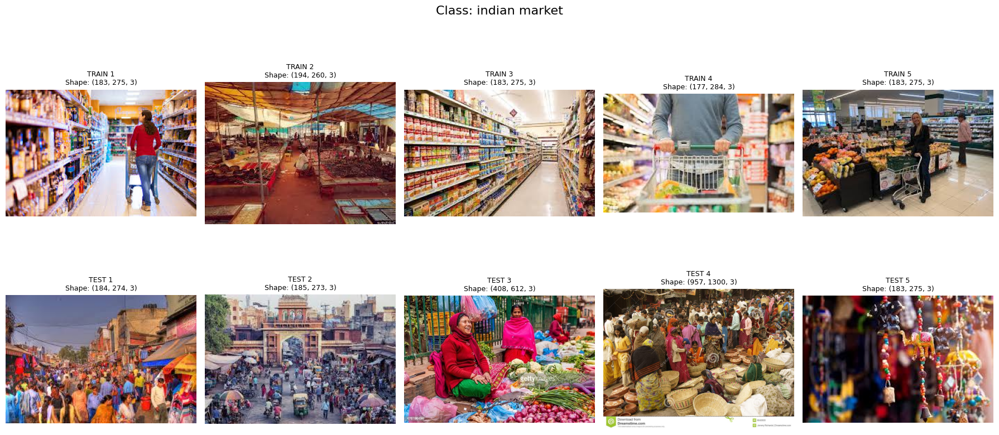

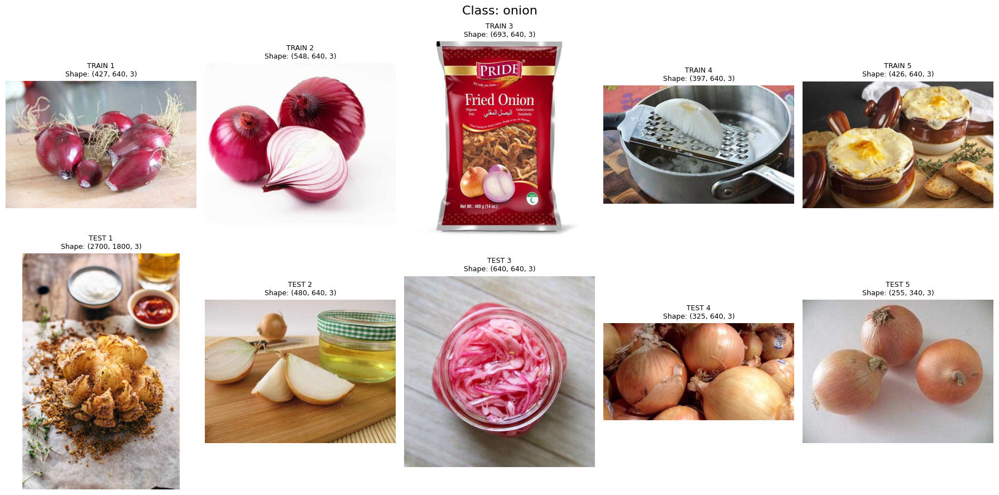

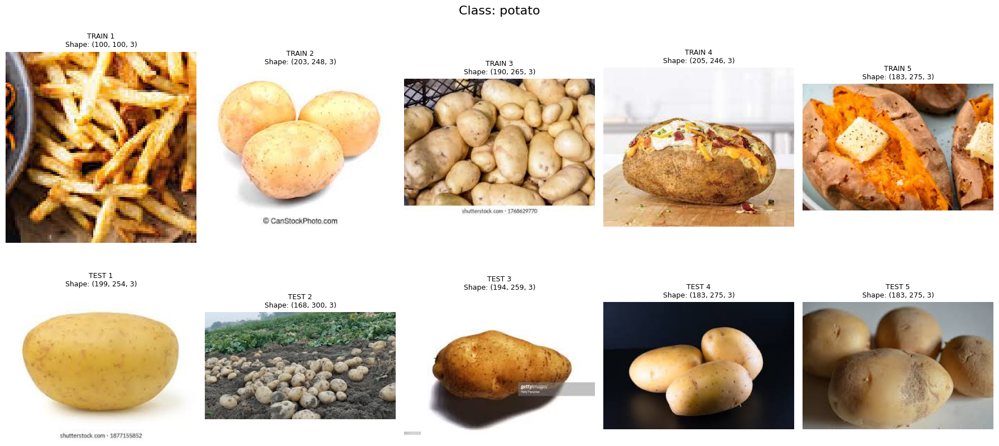

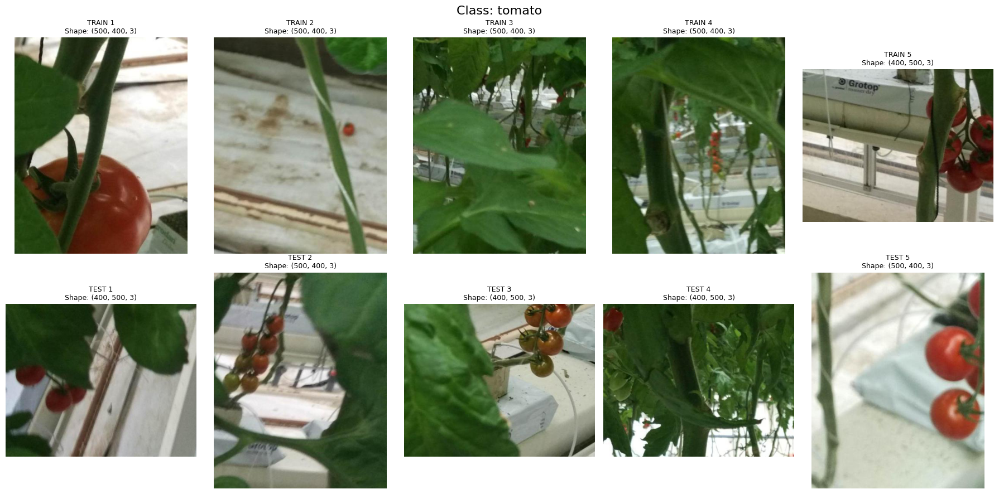

In [ ]:

visualize_dataset(train_dir, test_dir, num_images=5, seed=SEED)

## Detecting and deleting duplicates

In [ ]:

def create_unique_dataset(base_dir, output_dir, extensions):

    duplicates = defaultdict(list)
    original_counts = {"TRAIN": 0, "TEST": 0}
    unique_counts = {"TRAIN": 0, "TEST": 0}
    seen_hashes = set()
    total_duplicates = 0
    duplicate_groups = 0

    print("=" * 50)
    print("ORIGINAL DATASET SUMMARY")
    print("=" * 50)

    for split in ["train", "test"]:
        split_dir = os.path.join(base_dir, split)
        for root, dirs, files in os.walk(split_dir):
            dirs.sort()     # Sort directories for deterministic traversal
            for file in sorted(files): # Sort files for deterministic traversal
                if not file.lower().endswith(extensions):
                    continue

                path = os.path.join(root, file)
                class_name = os.path.basename(root)
                original_counts[split.upper()] += 1
                with open(path, "rb") as f:
                    file_hash = hashlib.sha256(f.read()).hexdigest()

                duplicates[file_hash].append({
                    "Image": file,
                    "Class": class_name,
                    "Dataset": split.upper(),
                    "Path": path
                })

    # Calculate duplicate statistics

    total_images = sum(original_counts.values())
    unique_hashes = len(duplicates)
    duplicate_groups = sum(
        1 for group in duplicates.values() if len(group) > 1
    )
    duplicate_images = sum(
        len(group) for group in duplicates.values()
        if len(group) > 1
    )

    duplicate_copies = total_images - unique_hashes

    print(f"Train Images              : {original_counts['TRAIN']}")
    print(f"Test Images               : {original_counts['TEST']}")
    print(f"Total Images              : {total_images}")
    print(f"Unique Images             : {unique_hashes}")
    print(f"Duplicate Groups          : {duplicate_groups}")
    print(f"Images in Duplicate Groups: {duplicate_images}")
    print(f"Extra Duplicate Copies    : {duplicate_copies}")
    if duplicate_groups == 0:
        print("\nNo exact duplicate images found.")

    print("\n" + "=" * 50)
    print("CREATING UNIQUE DATASET")
    print("=" * 50)

    # Avoid accidentally copying an existing output
    if os.path.exists(output_dir):
        raise FileExistsError(
            f"Output directory already exists: {output_dir}"
        )

    pbar = tqdm(total=total_images, desc="Copying unique images")
    for split in ["train", "test"]:
        split_dir = os.path.join(base_dir, split)
        for root, dirs, files in os.walk(split_dir):
            dirs.sort()
            for file in sorted(files):
                if not file.lower().endswith(extensions):
                    continue
                pbar.update(1)

                source_path = os.path.join(root, file)
                with open(source_path, "rb") as f:
                    file_hash = hashlib.sha256(f.read()).hexdigest()

                # Skip previously encountered images
                if file_hash in seen_hashes:
                    total_duplicates += 1
                    continue

                seen_hashes.add(file_hash)

                # Preserve original directory structure
                relative_path = os.path.relpath(
                    source_path, base_dir
                )

                destination_path = os.path.join(
                    output_dir, relative_path
                )

                os.makedirs(
                    os.path.dirname(destination_path),
                    exist_ok=True
                )

                shutil.copy2(source_path, destination_path)

                unique_counts[split.upper()] += 1
    pbar.close()

    print("\n" + "=" * 50)
    print("UNIQUE DATASET SUMMARY")
    print("=" * 50)

    print(f"Train Images          : {unique_counts['TRAIN']}")
    print(f"Test Images           : {unique_counts['TEST']}")
    print(f"Total Unique Images   : {sum(unique_counts.values())}")
    print(f"Duplicates Skipped    : {total_duplicates}")

    print("\n" + "=" * 50)
    print("BEFORE vs AFTER")
    print("=" * 50)

    print(f"{'Metric':<25}{'Original':>12}{'Unique':>12}")

    print("-" * 49)

    print(
        f"{'Train Images':<25}"
        f"{original_counts['TRAIN']:>12}"
        f"{unique_counts['TRAIN']:>12}"
    )

    print(
        f"{'Test Images':<25}"
        f"{original_counts['TEST']:>12}"
        f"{unique_counts['TEST']:>12}"
    )

    print(
        f"{'Total Images':<25}"
        f"{total_images:>12}"
        f"{sum(unique_counts.values()):>12}"
    )

    print("\nOutput location:", output_dir)

    return duplicates, original_counts, unique_counts

In [ ]:

shutil.rmtree("ninjacart_data_unique", ignore_errors=True)
duplicates, original_counts, unique_counts = create_unique_dataset(
    base_dir="ninjacart_data",
    output_dir="ninjacart_data_unique",
    extensions=extensions
)

ORIGINAL DATASET SUMMARY
Train Images              : 3135
Test Images               : 351
Total Images              : 3486
Unique Images             : 3440
Duplicate Groups          : 43
Images in Duplicate Groups: 89
Extra Duplicate Copies    : 46

CREATING UNIQUE DATASET


Copying unique images: 100%|██████████| 3486/3486 [00:01<00:00, 2381.07it/s]


UNIQUE DATASET SUMMARY
Train Images          : 3095
Test Images           : 345
Total Unique Images   : 3440
Duplicates Skipped    : 46

BEFORE vs AFTER
Metric                       Original      Unique
-------------------------------------------------
Train Images                     3135        3095
Test Images                       351         345
Total Images                     3486        3440

Output location: ninjacart_data_unique


In [ ]:

base_dir = "ninjacart_data_unique"
train_dir='ninjacart_data_unique/train'
test_dir='ninjacart_data_unique/test'

# Train-Val-Test Split

In [ ]:

# Load training data
full_train_dataset = datasets.ImageFolder(train_dir)

# Stratified 80:20 train-validation split
targets = full_train_dataset.targets

splitter = StratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

train_indices, val_indices = next(
    splitter.split(full_train_dataset.samples, targets)
)

with open("split_indices.json", "w") as f:
    json.dump({"train": train_indices.tolist(), "val": val_indices.tolist()}, f)

train_dataset = Subset(full_train_dataset, train_indices)

# Separate dataset object with evaluation transformations
eval_train_dataset = datasets.ImageFolder(train_dir)

val_dataset = Subset(eval_train_dataset, val_indices)

# Test dataset
test_dataset = datasets.ImageFolder(test_dir)

assert full_train_dataset.class_to_idx == test_dataset.class_to_idx

In [ ]:

def dataset_summary(*datasets):

    # Get variable names
    frame = inspect.currentframe().f_back
    local_vars = frame.f_locals

    dataset_names = [
        next(
            (k for k, v in local_vars.items() if v is dataset),
            f"Dataset_{i+1}"
        )
        for i, dataset in enumerate(datasets)
    ]

    del frame

    all_counts = {}
    class_names = None

    for name, dataset in zip(dataset_names, datasets):

        indices = None
        current = dataset

        # Unwrap nested subsets
        while isinstance(current, Subset):

            if indices is None:
                indices = list(current.indices)
            else:
                indices = [current.indices[i] for i in indices]

            current = current.dataset

        if not hasattr(current, "classes") or not hasattr(current, "targets"):
            raise TypeError(
                f"{name}: Expected ImageFolder or Subset of ImageFolder, "
                f"but found {type(current).__name__}"
            )

        if class_names is None:
            class_names = current.classes

        elif class_names != current.classes:
            raise ValueError(f"Class mismatch found in {name}")

        targets = (
            [current.targets[i] for i in indices]
            if indices is not None
            else current.targets
        )

        counts = Counter(targets)

        all_counts[name] = [
            counts[idx] for idx in range(len(class_names))
        ]

    print("\n" + "=" * 100)
    print("DATASET SUMMARY")
    print("=" * 100)

    # Dynamic column width
    width = 20

    header = f"{'Class ID':<10}{'Class Name':<22}"

    for name in dataset_names:
        header += f"{name:^{width}}"

    header += f"{'Total':>12}"

    print(header)
    print("-" * len(header))

    for idx, class_name in enumerate(class_names):

        row = f"{idx:<10}{class_name:<22}"

        for name in dataset_names:

            count = all_counts[name][idx]
            total = sum(all_counts[name])

            percentage = (count / total * 100) if total else 0

            row += f"{count:>9,} ({percentage:5.1f}%)"

        total_count = sum(
            all_counts[name][idx] for name in dataset_names
        )

        row += f"{total_count:>12,}"

        print(row)

    print("-" * len(header))

    # Dataset totals
    row = f"{'':<10}{'TOTAL':<22}"

    for name in dataset_names:

        total = sum(all_counts[name])
        row += f"{total:>9,} ({100.0 if total else 0:5.1f}%)"

    grand_total = sum(sum(v) for v in all_counts.values())

    row += f"{grand_total:>12,}"

    print(row)
    print("=" * 100)

    num_classes = len(class_names)
    num_datasets = len(datasets)

    x = list(range(num_classes))
    bar_width = 0.8 / num_datasets

    fig, ax = plt.subplots(
        figsize=(max(12, num_classes * 1.4), 7)
    )

    for i, name in enumerate(dataset_names):

        values = all_counts[name]
        total = sum(values)

        positions = [
            pos - 0.4 + bar_width / 2 + i * bar_width
            for pos in x
        ]

        bars = ax.bar(
            positions,
            values,
            width=bar_width,
            label=name
        )

        # Percentage labels
        for bar, count in zip(bars, values):

            percentage = (count / total * 100) if total else 0

            ax.annotate(
                f"{percentage:.1f}%",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 4),
                textcoords="offset points",
                ha="center",
                fontsize=8,
                rotation=0
            )

    ax.set_xlabel("Classes")
    ax.set_ylabel("Number of Images")
    ax.set_title("Dataset Class Distribution (%)")

    ax.set_xticks(x)
    ax.set_xticklabels(class_names, rotation=45, ha="right")

    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()



DATASET SUMMARY
Class ID  Class Name               train_dataset        val_dataset         test_dataset           Total
--------------------------------------------------------------------------------------------------------
0         indian market               475 ( 19.2%)      119 ( 19.2%)       77 ( 22.3%)         671
1         onion                       679 ( 27.4%)      170 ( 27.5%)       83 ( 24.1%)         932
2         potato                      691 ( 27.9%)      172 ( 27.8%)       79 ( 22.9%)         942
3         tomato                      631 ( 25.5%)      158 ( 25.5%)      106 ( 30.7%)         895
--------------------------------------------------------------------------------------------------------
          TOTAL                     2,476 (100.0%)      619 (100.0%)      345 (100.0%)       3,440


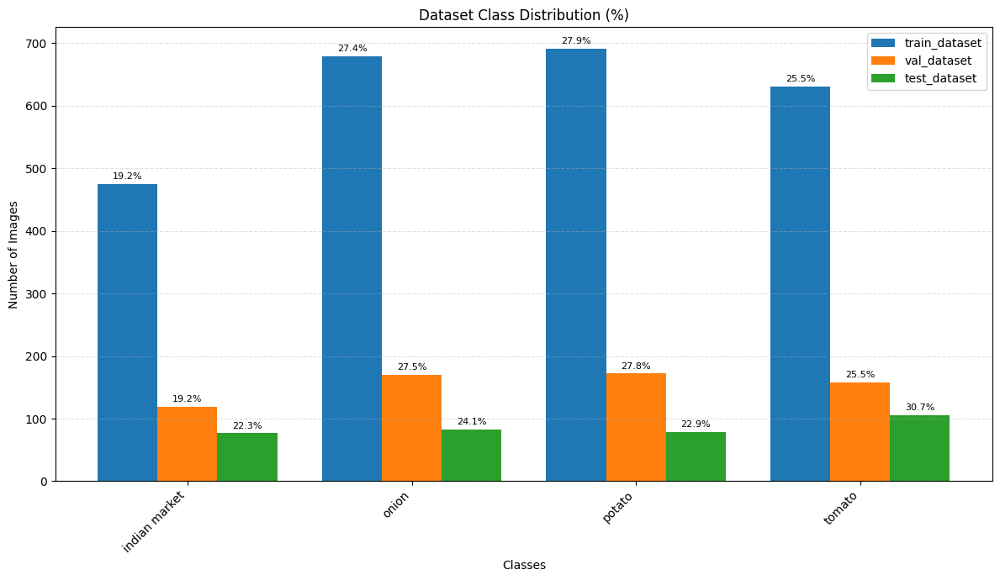

In [ ]:

dataset_summary(train_dataset, val_dataset, test_dataset)

# Important Helper Function/Class

In [ ]:

def get_base_and_indices(dataset):
    indices = None
    current = dataset
    while isinstance(current, Subset):
        if indices is None:
            indices = list(current.indices)
        else:
            indices = [current.indices[i] for i in indices]
        current = current.dataset
    return current, indices


# Recover original ImageFolder and indices
base_train, train_indices = get_base_and_indices(train_dataset)
base_val, val_indices = get_base_and_indices(val_dataset)

# Verify both came from the same original dataset
assert base_train.root == base_val.root

assert base_train.class_to_idx == base_val.class_to_idx
assert base_train.class_to_idx == test_dataset.class_to_idx

print("Class mappings match across all datasets.")

Class mappings match across all datasets.


In [ ]:
RESIZE_SHAPE = (224, 224)
class ResizeWithPadding:
    def __init__(self, resize_shape = (224, 224)):
        self.h, self.w = resize_shape

    def __call__(self, img):
        img = img.convert("RGB")
        # Resize proportionally; never crop
        img.thumbnail(
            (self.w, self.h),
            Image.Resampling.LANCZOS
        )
        # Calculate image-average RGB color for padding
        fill_color = tuple(
            np.array(img).mean(axis=(0, 1)).astype(int)
        )
        # Create canvas
        canvas = Image.new(
            "RGB",
            (self.w, self.h),
            fill_color
        )
        # Center the complete image
        x = (self.w - img.width) // 2
        y = (self.h - img.height) // 2
        canvas.paste(img, (x, y))
        return canvas

In [ ]:

def get_train_dataset_mean_std(base_train, train_indices, resize_shape = RESIZE_SHAPE, seed = 42):
    stats_transform = transforms.Compose([
        ResizeWithPadding(resize_shape),
        transforms.ToTensor()
    ])

    # Create a separate dataset for calculating statistics
    stats_full_dataset = datasets.ImageFolder(
        root=base_train.root,
        transform=stats_transform
    )

    stats_train_dataset = Subset(
        stats_full_dataset,
        train_indices
    )

    stats_loader = DataLoader(
        stats_train_dataset,
        batch_size=32,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=False,
        worker_init_fn=seed_worker,
        generator=get_generator(seed)
    )

    channel_sum = torch.zeros(3, dtype=torch.float64)
    channel_squared_sum = torch.zeros(3, dtype=torch.float64)
    total_pixels = 0

    for images, labels in stats_loader:
        images = images.double()
        # images shape: [B, c, h, w]
        batch_size, channels, height, width = images.shape
        pixels = batch_size * height * width
        channel_sum += images.sum(dim=[0, 2, 3])
        channel_squared_sum += (
            images ** 2
        ).sum(dim=[0, 2, 3])
        total_pixels += pixels

    # Calculate mean
    train_mean = channel_sum / total_pixels

    # Calculate population standard deviation
    train_variance = (channel_squared_sum / total_pixels) - (train_mean ** 2)
    train_std = torch.sqrt(train_variance.clamp(min=0))

    return train_mean.tolist(), train_std.tolist()

In [ ]:

def get_loaders(base_train, train_indices, val_indices, test_dataset, resize_shape = RESIZE_SHAPE, imagenet_stats = True, seed = 42, batch_size = 32, num_workers = 2):
    '''
    for mean, std default is ImageNet mean, std
    '''

    if imagenet_stats:
        mean = [0.485, 0.456, 0.406]
        std = [0.229, 0.224, 0.225]
        print("Using ImageNet mean, std.")
    else:
        mean, std = get_train_dataset_mean_std(base_train, train_indices, resize_shape = resize_shape, seed = seed)
        print("Using training dataset mean, std.")
    print(f"{mean = }\n{std = }")

    train_transform = transforms.Compose([
        ResizeWithPadding(resize_shape),
        transforms.RandomHorizontalFlip(p = 0.5),
        transforms.RandomRotation(degrees = 20),
        transforms.ColorJitter(
            brightness=0.15,
            contrast=0.15,
            saturation=0.15,
            hue=0.02
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=mean,
            std=std
        )
    ])

    eval_transform = transforms.Compose([
        ResizeWithPadding(resize_shape),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=mean,
            std=std
        )
    ])


    # Separate ImageFolder for training
    full_train_aug = datasets.ImageFolder(
        root=base_train.root,
        transform=train_transform
    )

    # Separate ImageFolder for validation
    full_train_eval = datasets.ImageFolder(
        root=base_train.root,
        transform=eval_transform
    )

    # Recreate subsets using original indices
    train_dataset = Subset(
        full_train_aug,
        train_indices
    )

    val_dataset = Subset(
        full_train_eval,
        val_indices
    )

    # Recreate test dataset
    test_root = test_dataset.root

    test_dataset = datasets.ImageFolder(
        root=test_root,
        transform=eval_transform
    )


    # Verify
    assert train_dataset.dataset.class_to_idx == val_dataset.dataset.class_to_idx
    assert train_dataset.dataset.class_to_idx == test_dataset.class_to_idx

    class_names = train_dataset.dataset.classes
    num_classes = len(class_names)

    print("Classes:", class_names)
    print("Number of classes:", num_classes)

    print("Train:", len(train_dataset))
    print("Validation:", len(val_dataset))
    print("Test:", len(test_dataset))

    # DataLoaders
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=(num_workers > 0),
        worker_init_fn=seed_worker,
        generator=get_generator(seed)
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=(num_workers > 0),
        worker_init_fn=seed_worker,
        generator=get_generator(seed)
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=(num_workers > 0),
        worker_init_fn=seed_worker,
        generator=get_generator(seed)
    )
    train_eval_loader = DataLoader(
        Subset(full_train_eval, train_indices),
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=(num_workers > 0),
        worker_init_fn=seed_worker
    )

    return train_loader, val_loader, test_loader, train_eval_loader, mean, std

In [ ]:

def start_experiment(exp_num, experiment_name):
    log_dir = f"runs/{exp_num} - {experiment_name}"
    shutil.rmtree(log_dir, ignore_errors=True)
    writer = SummaryWriter(log_dir=log_dir)
    print("TensorBoard log directory:", log_dir)
    print()
    return writer

In [ ]:

def train_one_epoch(model, loader, criterion, optimizer, device, scaler):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=AMP_ENABLED
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [ ]:

def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=AMP_ENABLED):
                outputs = model(images)
                loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += batch_size

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [ ]:

def start_training(model, optimizer, criterion, train_loader, val_loader, device, scaler, scheduler, epochs, exp_num, exp_name, patience=7, min_delta=0.0001, max_loss_gap = 0.03, seed = 42):
    set_seed(seed)

    writer = start_experiment(exp_num, exp_name)

    best_val_loss = float("inf")
    fallback_best_val_loss = float("inf")
    early_stop_counter = 0
    fallback_checkpoint = None
    best_epoch = -1
    high_gap_counter = 0

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    os.makedirs("models", exist_ok=True)
    best_model_path = f"models/{exp_num}.best_{exp_name}.pth"
    if os.path.exists(best_model_path):
        os.remove(best_model_path)

    for epoch in range(epochs):

        start_time = time.time()

        # Training
        train_loss, train_acc = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device,
            scaler
        )

        # Validation
        val_loss, val_acc = validate_one_epoch(
            model,
            val_loader,
            criterion,
            device
        )

        # Scheduler
        scheduler.step(val_loss)

        current_lr = optimizer.param_groups[0]["lr"]

        # History
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        # TensorBoard
        writer.add_scalar("Loss/Train", train_loss, epoch + 1)
        writer.add_scalar("Loss/Validation", val_loss, epoch + 1)

        writer.add_scalar("Accuracy/Train", train_acc, epoch + 1)
        writer.add_scalar("Accuracy/Validation", val_acc, epoch + 1)

        writer.add_scalar("Learning_Rate", current_lr, epoch + 1)

        loss_gap = val_loss - train_loss
        val_improved = val_loss < (best_val_loss - min_delta)
        gap_ok = loss_gap < max_loss_gap

        # Always track lowest val_loss as a fallback in case gap_ok never triggers
        if val_loss < fallback_best_val_loss:
            fallback_best_val_loss = val_loss
            fallback_checkpoint = {
                  "epoch": epoch + 1,
                  "model_state_dict": model.state_dict(),
                  "optimizer_state_dict": optimizer.state_dict(),
                  "best_val_loss": fallback_best_val_loss,
                  "train_loss": train_loss,
                  "val_loss": val_loss,
                  "loss_gap": loss_gap,
            }

        # Save best model when val_loss improves AND loss_gap is within limit
        if val_improved and gap_ok:
            best_val_loss = val_loss
            best_epoch = epoch + 1

            torch.save({
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
                "train_loss": train_loss,
                "val_loss": val_loss,
                "loss_gap": loss_gap
            }, best_model_path)

            early_stop_counter = 0
            best_marker = " * BEST"

        elif val_improved and not gap_ok:
            # Val loss improved, but gap exceeded max_loss_gap: don't save as strict best, and log/track high_gap_counter instead of treating it as a flat val_loss
            high_gap_counter += 1
            best_marker = " (SKIPPED: val_loss improved but, gap exceeded max_loss_gap)"

        else:
            high_gap_counter = 0 if gap_ok else high_gap_counter + 1
            early_stop_counter += 1
            best_marker = ""

        elapsed = time.time() - start_time

        print(
            f"Epoch [{epoch+1:02d}/{epochs}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Acc: {val_acc:.2f}% | "
            f"LR: {current_lr:.6f} | "
            f"Time: {elapsed:.1f}s"
            f"{best_marker}"
        )

        # Early stopping
        if early_stop_counter >= patience:
            print(f"\nEarly stopping at epoch {epoch+1}")
            break

    if not os.path.exists(best_model_path) and fallback_checkpoint is not None:
        print("No epoch met both val_loss improvement and loss_gap < max_loss_gap; saving lowest val_loss fallback checkpoint.")
        torch.save(fallback_checkpoint, best_model_path)

    writer.close()
    assert os.path.exists(best_model_path), "No checkpoint saved: val_loss never met the gap condition"
    with open(f"{exp_num}.history.json", "w") as f:
        json.dump(history, f)

    print("\nTraining completed.")
    print("Best epoch:", best_epoch)
    print("Best validation loss:", best_val_loss)
    print("Best model:", best_model_path)

    return history, best_model_path, best_epoch

In [ ]:

def plot_train_val(history):
    epochs_range = range(1, len(history["train_loss"]) + 1)

    # Loss plot
    plt.figure(figsize=(18, 5))

    plt.plot(
        epochs_range,
        history["train_loss"],
        label="Training Loss"
    )

    plt.plot(
        epochs_range,
        history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")

    plt.legend()
    plt.grid(True)
    plt.show()


    # Accuracy plot
    plt.figure(figsize=(18, 5))

    plt.plot(
        epochs_range,
        history["train_acc"],
        label="Training Accuracy"
    )

    plt.plot(
        epochs_range,
        history["val_acc"],
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title("Training vs Validation Accuracy")

    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:

def _loader_paths(loader):
    """File paths in the order the loader yields them (valid only when shuffle=False)."""
    ds = loader.dataset
    if isinstance(ds, Subset):
        return [ds.dataset.samples[i][0] for i in ds.indices]
    return [s[0] for s in ds.samples]


def evaluate_model(model, criterion, device, loaders, keep_correct_images=False):
    """
    Returns four dicts keyed by split name (the keys of `loaders`):
      y_true[split], y_pred[split]            -> lists
      misclassified[split]                    -> list of dicts (with "image")
      correct_classified[split]               -> list of dicts (no "image" unless keep_correct_images=True)
    Each dict: actual, predicted, confidence, index, path (+ image).
    """
    model.eval()

    y_true, y_pred = {}, {}
    misclassified, correct_classified = {}, {}

    for name, loader in loaders.items():

        if isinstance(loader.sampler, RandomSampler):
            warnings.warn(
                f"'{name}' loader is shuffled, so 'index' and 'path' cannot be traced. "
                f"Use a shuffle=False, non-augmented loader (e.g. train_eval_loader)."
            )
            paths = None
        else:
            paths = _loader_paths(loader)

        y_true[name], y_pred[name] = [], []
        misclassified[name], correct_classified[name] = [], []

        running_loss, correct, total, position = 0.0, 0, 0, 0

        with torch.no_grad():
            for images, labels in loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                probs = F.softmax(outputs, dim=1)
                confidences, preds = probs.max(dim=1)

                batch_size = labels.size(0)
                running_loss += loss.item() * batch_size
                correct += (preds == labels).sum().item()
                total += batch_size

                labels_cpu = labels.cpu().tolist()
                preds_cpu = preds.cpu().tolist()
                conf_cpu = confidences.cpu().tolist()

                y_true[name].extend(labels_cpu)
                y_pred[name].extend(preds_cpu)

                for i in range(batch_size):
                    record = {
                        "actual": labels_cpu[i],
                        "predicted": preds_cpu[i],
                        "confidence": conf_cpu[i],
                        "index": position + i,
                        "path": paths[position + i] if paths is not None else None,
                    }
                    if labels_cpu[i] != preds_cpu[i]:
                        record["image"] = images[i].cpu().clone()
                        misclassified[name].append(record)
                    else:
                        if keep_correct_images:
                            record["image"] = images[i].cpu().clone()
                        correct_classified[name].append(record)

                position += batch_size

        print("=" * 45)
        print(f"{name} RESULTS")
        print("=" * 45)
        print(f"{name} Loss          : {running_loss / total:.4f}")
        print(f"{name} Accuracy      : {100 * correct / total:.2f}%")
        print(f"{name} Misclassified : {len(misclassified[name])} / {total}")
        print()

    return y_true, y_pred, misclassified, correct_classified

In [ ]:

def model_report(y_true, y_pred, class_names, model_name="Model"):

    # Classification report
    report = classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )

    # Confusion matrix
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=range(len(class_names))
    )

    # Side-by-side plots
    fig, axes = plt.subplots(
        1, 2,
        figsize=(16, 6),
        gridspec_kw={"width_ratios": [1, 1.2], "wspace" : 0.05}
    )

    # Classification report
    axes[0].axis("off")

    axes[0].text(
        0.05, 1,
        report,
        fontsize=11,
        fontfamily="monospace",
        verticalalignment="top"
    )

    axes[0].set_title(
        f"{model_name} - Classification Report",
        fontsize=16,
        fontweight="bold"
    )

    # Confusion matrix
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        cmap="Blues",
        ax=axes[1],
        values_format="d",
        colorbar=False
    )

    axes[1].set_title(
        f"{model_name} - Confusion Matrix",
        fontsize=13,
        fontweight="bold"
    )

    axes[1].tick_params(axis="x", rotation=45)

    # plt.tight_layout()
    plt.show()

    return cm, report

In [ ]:

def error_counts_summary(mis, class_names, correct=None, splits=None):
    """Prints actual -> predicted error counts for each split, then a side-by-side table.
    Returns the long-form DataFrame (Split, Actual, Predicted, Count)."""
    splits = splits or list(mis.keys())
    rows = []

    for split in splits:
        errors = mis[split]
        counts = Counter(
            (class_names[x["actual"]], class_names[x["predicted"]]) for x in errors
        )

        header = f"{split}: {len(errors)} misclassified"
        if correct is not None:
            total = len(errors) + len(correct[split])
            header += f" / {total} images ({100 * len(errors) / total:.2f}% error)"

        print("=" * 60)
        print(header)
        print("=" * 60)
        if not counts:
            print("No errors.\n")
            continue

        print(f"{'Actual':<18}{'':<4}{'Predicted':<18}{'Count':>6}{'% of errors':>13}")
        print("-" * 60)
        for (actual, predicted), c in counts.most_common():
            print(f"{actual:<18}{'->':<4}{predicted:<18}{c:>6}{100 * c / len(errors):>12.1f}%")
            rows.append({"Split": split, "Actual": actual, "Predicted": predicted, "Count": c})
        print()

    # df = pd.DataFrame(rows, columns=["Split", "Actual", "Predicted", "Count"])
    # if df.empty:
    #     return df

    # side_by_side = (
    #     df.pivot_table(index=["Actual", "Predicted"], columns="Split",
    #                    values="Count", aggfunc="sum", fill_value=0)
    #       .reindex(columns=splits, fill_value=0)
    # )
    # side_by_side["Total"] = side_by_side.sum(axis=1)
    # print("SIDE BY SIDE")
    # display(side_by_side.sort_values("Total", ascending=False))
    # return df

In [ ]:

def show_misclassified_gradcam(
    misclassified,
    class_names,
    model,
    target_layer,
    actual_class=None,
    predicted_class=None,
    mean=None,
    std=None,
    cam_for="predicted",   # "predicted", "actual", or "both"
    max_images=None,       # None = show all matches
    alpha=0.45,
    title=None
):
    # ---- filter (same as before) ----
    selected = misclassified
    if actual_class is not None:
        selected = [x for x in selected if class_names[x["actual"]] == actual_class]
    if predicted_class is not None:
        selected = [x for x in selected if class_names[x["predicted"]] == predicted_class]
    if len(selected) == 0:
        print("No matching images found.")
        return
    if max_images is not None:
        selected = selected[:max_images]

    # ---- layout: [original | CAM] per image, ~4 columns total ----
    cam_keys = {"predicted": ["predicted"],
                "actual": ["actual"],
                "both": ["predicted", "actual"]}[cam_for]
    panels = 1 + len(cam_keys)
    per_row = max(1, 4 // panels)
    cols = per_row * panels
    rows = math.ceil(len(selected) / per_row)

    fig, axes = plt.subplots(rows, cols, figsize=(3.4 * cols, 3.9 * rows), squeeze=False)
    for ax in axes.flatten():
        ax.axis("off")

    title_parts = []
    if actual_class:
        title_parts.append(f"Actual: {actual_class}")
    if predicted_class:
        title_parts.append(f"Predicted: {predicted_class}")
    title_str = title or (" - ".join(title_parts) if title_parts else "Misclassified Images + Grad-CAM")
    fig.suptitle(title_str, fontsize=16, fontweight="bold", color="navy", y=1.02)

    # ---- Grad-CAM hooks on the target conv layer ----
    store = {}

    def forward_hook(module, inputs, output):
        store["activations"] = output.detach()
        output.register_hook(lambda grad: store.update(gradients=grad.detach()))

    handle = target_layer.register_forward_hook(forward_hook)
    model.eval()

    try:
        for n, item in enumerate(selected):
            row, slot = divmod(n, per_row)
            col = slot * panels

            image = item["image"]
            rgb = image.clone()
            if mean is not None and std is not None:
                m = torch.tensor(mean, dtype=rgb.dtype).view(3, 1, 1)
                s = torch.tensor(std, dtype=rgb.dtype).view(3, 1, 1)
                rgb = rgb * s + m
            rgb = rgb.clamp(0, 1).permute(1, 2, 0).cpu().numpy()

            actual = class_names[item["actual"]]
            predicted = class_names[item["predicted"]]
            confidence = item["confidence"] * 100

            # forward + one backward per requested class
            x = image.unsqueeze(0).to(device).requires_grad_(True)
            cams = []
            with torch.enable_grad():
                model.zero_grad(set_to_none=True)
                logits = model(x)
                probs = F.softmax(logits, dim=1)[0].detach().cpu()

                for key in cam_keys:
                    class_idx = item[key]
                    model.zero_grad(set_to_none=True)
                    logits[0, class_idx].backward(retain_graph=True)

                    weights = store["gradients"].mean(dim=(2, 3), keepdim=True)
                    cam = F.relu((weights * store["activations"]).sum(dim=1, keepdim=True))
                    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear",
                                        align_corners=False)[0, 0]
                    cam = cam - cam.min()
                    cam = (cam / (cam.max() + 1e-8)).cpu().numpy()
                    cams.append((key, class_idx, cam))

            # panel 1: original, same title as before
            ax = axes[row, col]
            ax.imshow(rgb)
            ax.set_title(
                f"Actual: {actual}\n"
                f"Predicted: {predicted}\n"
                f"Confidence: {confidence:.1f}%",
                fontsize=9
            )

            # panel(s) 2..: Grad-CAM overlay
            for j, (key, class_idx, cam) in enumerate(cams, start=1):
                heat = plt.get_cmap("jet")(cam)[..., :3]
                ax = axes[row, col + j]
                ax.imshow(np.clip((1 - alpha) * rgb + alpha * heat, 0, 1))
                ax.set_title(
                    f"Grad-CAM for {key.upper()}\n"
                    f"{class_names[class_idx]}\n"
                    f"prob: {probs[class_idx] * 100:.1f}%",
                    fontsize=9
                )
    finally:
        handle.remove()

    plt.tight_layout()

    # 1. Give extra vertical room between rows for 3-line titles
    fig.subplots_adjust(hspace=0.65)

    # 2. Draw horizontal separator lines cleanly above next-row titles
    if rows > 1:
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        inv_fig = fig.transFigure.inverted()

        all_axes = axes.ravel()
        left_x = min(ax.get_position().x0 for ax in all_axes)
        right_x = max(ax.get_position().x1 for ax in all_axes)

        for r in range(rows - 1):
            # Lowest bottom edge of row r's axes (in figure coords)
            bottom_y = min(ax.get_position().y0 for ax in axes[r])

            # Highest top edge of row r+1 including its title text (in figure coords)
            top_y = max(ax.get_position().y1 for ax in axes[r + 1])
            for ax in axes[r + 1]:
                title_bb = ax.title.get_window_extent(renderer=renderer)
                if title_bb.width > 0 and title_bb.height > 0:
                    _, title_top_fig = inv_fig.transform((0, title_bb.y1))
                    top_y = max(top_y, title_top_fig)

            mid_y = 0.5 * (bottom_y + top_y)

            line = plt.Line2D(
                [left_x, right_x],
                [mid_y, mid_y],
                transform=fig.transFigure,
                color="gray",
                linewidth=1.2,
                linestyle="--",
                alpha=0.8,
            )
            fig.add_artist(line)

    plt.show()

In [ ]:

def _load_eval_tensor(path, mean, std, resize_shape):
    """Rebuilds the exact eval-transform tensor from a file (used when images weren't stored)."""
    tf = transforms.Compose([
        ResizeWithPadding(resize_shape),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])
    with Image.open(path) as img:
        return tf(img)


def show_gradcam_by_split(
    mis, correct, class_names, model, target_layer, mean, std,
    splits=None,                 # e.g. ["Train", "Test"]; None = all splits in mis
    show=("mis", "correct"),     # any of "mis", "correct"
    max_img=8,
    actual_class=None, predicted_class=None,
    order="auto",                # "auto", "high", "low", "random"
    cam_for="predicted",         # for misclassified: "predicted", "actual" or "both"
    seed=42,
    resize_shape=RESIZE_SHAPE,
):
    """
    order="auto": misclassified -> most confident mistakes first (likely label noise),
                  correct       -> least confident first (borderline cases).
    Selection is deterministic (random uses `seed`).
    """
    splits = splits or list(mis.keys())
    groups = {"mis": ("MISCLASSIFIED", mis), "correct": ("CORRECTLY CLASSIFIED", correct)}

    for split in splits:
        for kind in show:
            label, source = groups[kind]
            if source is None:
                print(f"{split} | {label}: no data (pass `correct` to see these).")
                continue

            # filter
            items = list(source[split])
            if actual_class is not None:
                items = [x for x in items if class_names[x["actual"]] == actual_class]
            if predicted_class is not None:
                items = [x for x in items if class_names[x["predicted"]] == predicted_class]
            matched = len(items)
            if matched == 0:
                print(f"{split} | {label}: no matching images.")
                continue

            # order, then take max_img
            how = order if order != "auto" else ("high" if kind == "mis" else "low")
            if how == "high":
                items.sort(key=lambda x: -x["confidence"])
            elif how == "low":
                items.sort(key=lambda x: x["confidence"])
            elif how == "random":
                random.Random(seed).shuffle(items)
            if max_img:
                items = items[:max_img]

            # make sure each selected item has its tensor (reload from file if not stored)
            ready = []
            for x in items:
                if "image" not in x:
                    if x.get("path") is None:
                        continue   # no image and no path: cannot draw
                    x = {**x, "image": _load_eval_tensor(x["path"], mean, std, resize_shape)}
                ready.append(x)
            if not ready:
                print(f"{split} | {label}: images not stored and paths unavailable.")
                continue

            filters = []
            if actual_class:
                filters.append(f"actual={actual_class}")
            if predicted_class:
                filters.append(f"predicted={predicted_class}")
            title = f"{split} - {label} ({len(ready)} of {matched})"
            if filters:
                title += " - " + ", ".join(filters)

            show_misclassified_gradcam(
                ready, class_names, model, target_layer,
                mean=mean, std=std,
                cam_for=(cam_for if kind == "mis" else "predicted"),  # actual == predicted for correct
                title=title,
            )

# Notebook Global Var

In [ ]:

class_names = full_train_dataset.classes
BATCH_SIZE = 32
NUM_WORKERS = 2
NUM_CLASSES = len(class_names)

lr = 0.001
weight_decay = 0.0001
EPOCHS = 40

# Models Train/Validate/Test

## Custom CNN

### Baseline

In [ ]:

EXP_NUM = 1
EXP_NAME = 'CustomCNN - Baseline'

In [ ]:

class CustomCNN_base(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        # Block 1
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2)
        )

        # Block 2
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2)
        )

        # Block 3
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2)
        )

        # Global Average Pooling
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Classifier
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, num_classes)
        )


    def forward(self, x):

        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)

        x = self.global_pool(x)

        x = self.classifier(x)

        return x

summary(CustomCNN_base(num_classes=NUM_CLASSES).to(device), input_size=(1, 3, *RESIZE_SHAPE))

Layer (type:depth-idx)                   Output Shape              Param #
CustomCNN_base                           [1, 4]                    --
├─Sequential: 1-1                        [1, 32, 112, 112]         --
│    └─Conv2d: 2-1                       [1, 32, 224, 224]         896
│    └─ReLU: 2-2                         [1, 32, 224, 224]         --
│    └─MaxPool2d: 2-3                    [1, 32, 112, 112]         --
├─Sequential: 1-2                        [1, 64, 56, 56]           --
│    └─Conv2d: 2-4                       [1, 64, 112, 112]         18,496
│    └─ReLU: 2-5                         [1, 64, 112, 112]         --
│    └─MaxPool2d: 2-6                    [1, 64, 56, 56]           --
├─Sequential: 1-3                        [1, 128, 28, 28]          --
│    └─Conv2d: 2-7                       [1, 128, 56, 56]          73,856
│    └─ReLU: 2-8                         [1, 128, 56, 56]          --
│    └─MaxPool2d: 2-9                    [1, 128, 28, 28]          --
├─Adap

In [ ]:

set_seed(SEED)
train_loader, val_loader, test_loader, train_eval_loader, mean, std = get_loaders(
    base_train, train_indices, val_indices, test_dataset,
    resize_shape=RESIZE_SHAPE, imagenet_stats=False,
    seed=SEED, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)

set_seed(SEED)
model_cnn_base = CustomCNN_base(num_classes=NUM_CLASSES).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model_cnn_base.parameters(), lr=lr, weight_decay=weight_decay)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3, threshold=0.001, min_lr=1e-7)
scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)

history, best_model_path, best_epoch = start_training(
    model_cnn_base, optimizer, criterion, train_loader, val_loader, device, scaler, scheduler,
    epochs=EPOCHS, exp_num=EXP_NUM, exp_name=EXP_NAME)

Using training dataset mean, std.
mean = [0.5586165273534793, 0.4952166374869274, 0.40806714412483647]
std = [0.26263477344328234, 0.24459292432825713, 0.2638448892539471]
Classes: ['indian market', 'onion', 'potato', 'tomato']
Number of classes: 4
Train: 2476
Validation: 619
Test: 345
TensorBoard log directory: runs/1 - CustomCNN - Baseline

Epoch [01/40] Train Loss: 1.0545 | Val Loss: 0.9374 | Train Acc: 51.98% | Val Acc: 58.64% | LR: 0.001000 | Time: 19.2s * BEST
Epoch [02/40] Train Loss: 0.7824 | Val Loss: 0.6984 | Train Acc: 68.17% | Val Acc: 73.02% | LR: 0.001000 | Time: 18.6s * BEST
Epoch [03/40] Train Loss: 0.6818 | Val Loss: 0.7063 | Train Acc: 74.31% | Val Acc: 72.70% | LR: 0.001000 | Time: 18.5s
Epoch [04/40] Train Loss: 0.6309 | Val Loss: 0.6952 | Train Acc: 74.43% | Val Acc: 71.57% | LR: 0.001000 | Time: 18.6s (SKIPPED: val_loss improved but, gap exceeded max_loss_gap)
Epoch [05/40] Train Loss: 0.5683 | Val Loss: 0.5340 | Train Acc: 77.34% | Val Acc: 78.68% | LR: 0.001000 

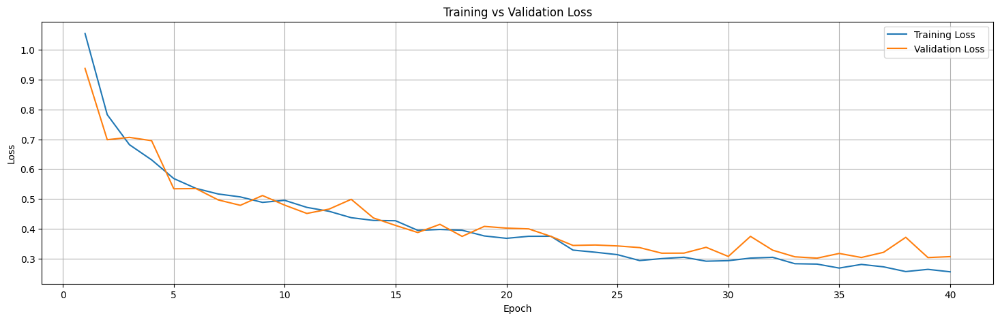

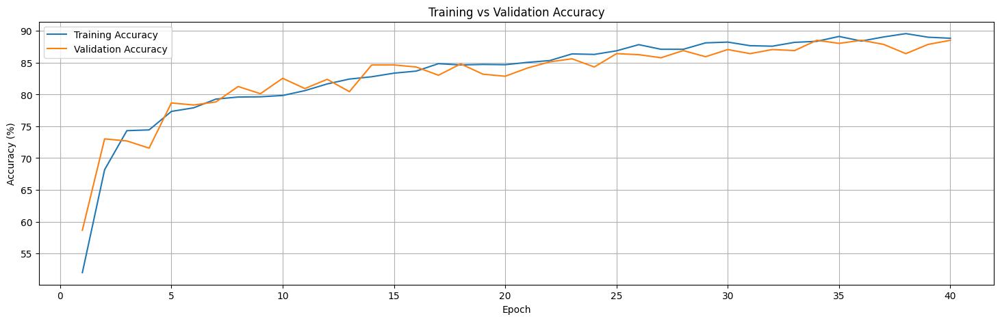

In [ ]:

plot_train_val(history)

In [ ]:

set_seed()

model_cnn_base = CustomCNN_base(
    num_classes=NUM_CLASSES
).to(device)

# if num_gpus > 1:
#     model_cnn = nn.DataParallel(model_cnn)

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True
)

model_cnn_base.load_state_dict(checkpoint["model_state_dict"])

<All keys matched successfully>

In [ ]:
eval_loaders = {"Train": train_eval_loader, "Validation": val_loader, "Test": test_loader}
y_true, y_pred, mis, correct = evaluate_model(model_cnn_base, criterion, device, eval_loaders)

# sanity checks
assert len(y_true["Train"]) == len(train_indices)
assert len(mis["Train"]) + len(correct["Train"]) == len(train_indices)

Train RESULTS
Train Loss          : 0.2397
Train Accuracy      : 90.06%
Train Misclassified : 246 / 2476

Validation RESULTS
Validation Loss          : 0.3014
Validation Accuracy      : 88.53%
Validation Misclassified : 71 / 619

Test RESULTS
Test Loss          : 0.3735
Test Accuracy      : 84.93%
Test Misclassified : 52 / 345



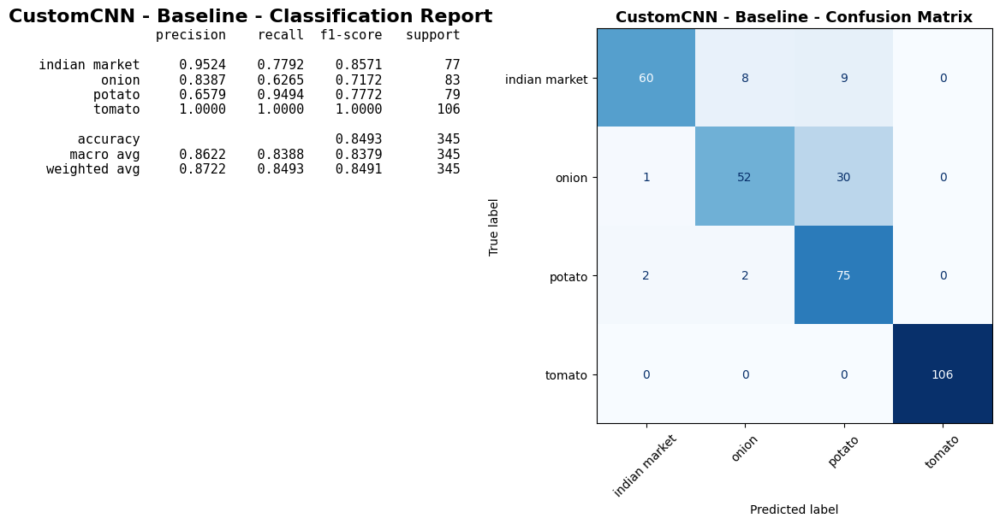

In [ ]:
cm, re = model_report(y_true["Test"], y_pred["Test"], class_names, model_name=EXP_NAME)

In [ ]:
print(re)

               precision    recall  f1-score   support

indian market     0.9524    0.7792    0.8571        77
        onion     0.8387    0.6265    0.7172        83
       potato     0.6579    0.9494    0.7772        79
       tomato     1.0000    1.0000    1.0000       106

     accuracy                         0.8493       345
    macro avg     0.8622    0.8388    0.8379       345
 weighted avg     0.8722    0.8493    0.8491       345



In [ ]:
# counts for all three splits
error_counts_summary(mis, class_names, correct=correct)

Train: 246 misclassified / 2476 images (9.94% error)
Actual                Predicted          Count  % of errors
------------------------------------------------------------
onion             ->  potato               158        64.2%
potato            ->  onion                 33        13.4%
onion             ->  indian market         20         8.1%
indian market     ->  onion                 12         4.9%
indian market     ->  potato                10         4.1%
potato            ->  indian market          9         3.7%
onion             ->  tomato                 2         0.8%
potato            ->  tomato                 1         0.4%
tomato            ->  onion                  1         0.4%

Validation: 71 misclassified / 619 images (11.47% error)
Actual                Predicted          Count  % of errors
------------------------------------------------------------
onion             ->  potato                39        54.9%
potato            ->  onion                 13 

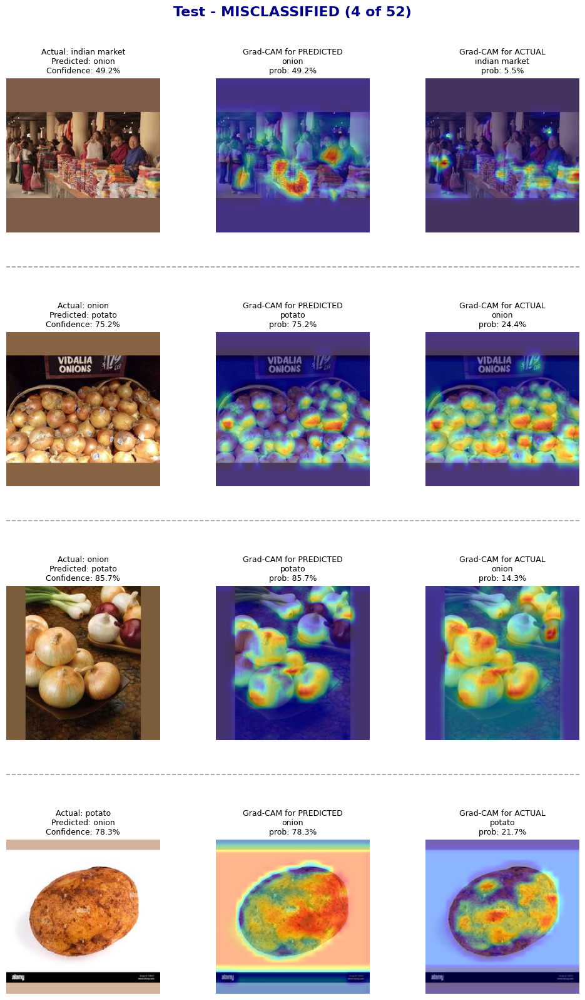

In [ ]:
# Grad-CAM
# show_gradcam_by_split(mis, correct, class_names, model_cnn, model_cnn.block4, mean, std, splits = ['Test'], show = ('mis',), max_img = None, order = 'high', cam_for="predicted")
# one split, errors only, one confusion pair, show where it looked for BOTH classes
show_gradcam_by_split(mis, correct, class_names, model_cnn_base, model_cnn_base.block3, mean, std,
                      splits=["Test"], show=("mis",),max_img=4, cam_for="both", order = "random", seed=43)

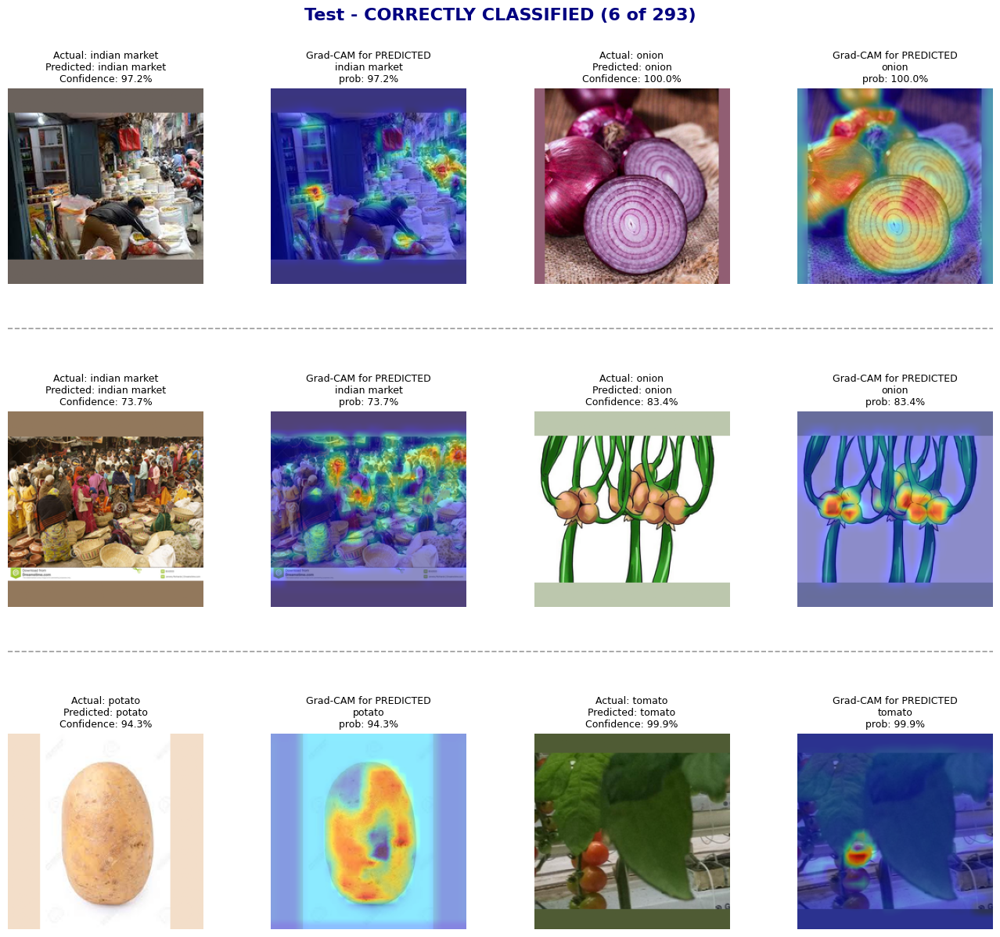

In [ ]:
show_gradcam_by_split(mis, correct, class_names, model_cnn_base, model_cnn_base.block3, mean, std,
                      splits=["Test"], show=("correct",), max_img=6, cam_for="both", order = "random", seed = 99)

### CustomCNN with dropout, batchnorm

Insted of only covolution and dense layers, i implemented batchnorm, dropout, globalpooling includin convolution and dense

In [ ]:
EXP_NUM = 2
EXP_NAME = 'CustomCNN - BN & dropout'

In [ ]:

class CustomCNN(nn.Module):

    def __init__(self, num_classes, dropout = 0.3):

        super().__init__()

        # Block 1
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2)
        )

        # Block 2
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2)
        )

        # Block 3
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2)
        )

        # Block 4
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2)
        )

        # Global Average Pooling
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Classifier
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )


    def forward(self, x):

        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)

        x = self.global_pool(x)

        x = self.classifier(x)

        return x

summary(CustomCNN(num_classes=NUM_CLASSES).to(device), input_size=(1, 3, *RESIZE_SHAPE))

Layer (type:depth-idx)                   Output Shape              Param #
CustomCNN                                [1, 4]                    --
├─Sequential: 1-1                        [1, 32, 112, 112]         --
│    └─Conv2d: 2-1                       [1, 32, 224, 224]         896
│    └─BatchNorm2d: 2-2                  [1, 32, 224, 224]         64
│    └─ReLU: 2-3                         [1, 32, 224, 224]         --
│    └─MaxPool2d: 2-4                    [1, 32, 112, 112]         --
├─Sequential: 1-2                        [1, 64, 56, 56]           --
│    └─Conv2d: 2-5                       [1, 64, 112, 112]         18,496
│    └─BatchNorm2d: 2-6                  [1, 64, 112, 112]         128
│    └─ReLU: 2-7                         [1, 64, 112, 112]         --
│    └─MaxPool2d: 2-8                    [1, 64, 56, 56]           --
├─Sequential: 1-3                        [1, 128, 28, 28]          --
│    └─Conv2d: 2-9                       [1, 128, 56, 56]          73,856
│    

In [ ]:

set_seed(SEED)
train_loader, val_loader, test_loader, train_eval_loader, mean, std = get_loaders(
    base_train, train_indices, val_indices, test_dataset,
    resize_shape=RESIZE_SHAPE, imagenet_stats=False,
    seed=SEED, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)

set_seed(SEED)
model_cnn = CustomCNN(num_classes=NUM_CLASSES).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model_cnn.parameters(), lr=lr, weight_decay=weight_decay)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3, threshold=0.001, min_lr=1e-7)
scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)

history, best_model_path, best_epoch = start_training(
    model_cnn, optimizer, criterion, train_loader, val_loader, device, scaler, scheduler,
    epochs=EPOCHS, exp_num=EXP_NUM, exp_name=EXP_NAME)

Using training dataset mean, std.
mean = [0.5586165273534793, 0.4952166374869274, 0.40806714412483647]
std = [0.26263477344328234, 0.24459292432825713, 0.2638448892539471]
Classes: ['indian market', 'onion', 'potato', 'tomato']
Number of classes: 4
Train: 2476
Validation: 619
Test: 345
TensorBoard log directory: runs/2 - CustomCNN - BN & dropout

Epoch [01/40] Train Loss: 0.7073 | Val Loss: 0.5147 | Train Acc: 71.12% | Val Acc: 79.64% | LR: 0.001000 | Time: 19.4s * BEST
Epoch [02/40] Train Loss: 0.5782 | Val Loss: 0.5704 | Train Acc: 77.46% | Val Acc: 77.71% | LR: 0.001000 | Time: 18.9s
Epoch [03/40] Train Loss: 0.5303 | Val Loss: 0.4414 | Train Acc: 79.64% | Val Acc: 82.71% | LR: 0.001000 | Time: 18.3s * BEST
Epoch [04/40] Train Loss: 0.4416 | Val Loss: 0.6307 | Train Acc: 83.40% | Val Acc: 78.51% | LR: 0.001000 | Time: 18.5s
Epoch [05/40] Train Loss: 0.4444 | Val Loss: 0.4041 | Train Acc: 82.07% | Val Acc: 82.39% | LR: 0.001000 | Time: 18.7s * BEST
Epoch [06/40] Train Loss: 0.4334 | 

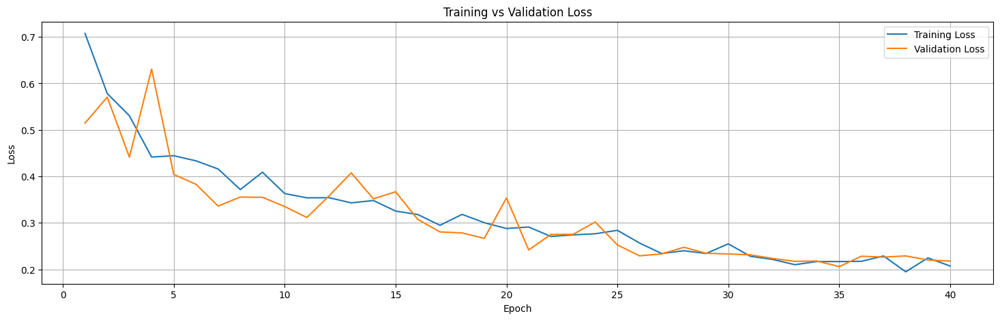

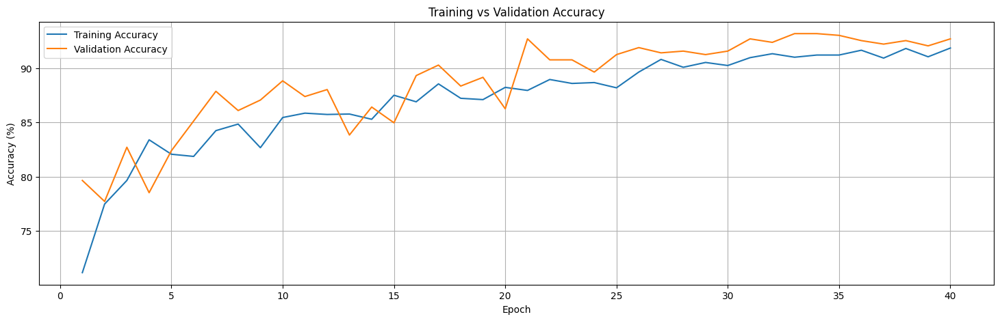

In [ ]:
plot_train_val(history)

In [ ]:
set_seed()

model_cnn = CustomCNN(
    num_classes=NUM_CLASSES
).to(device)

# if num_gpus > 1:
#     model_cnn = nn.DataParallel(model_cnn)

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True
)

model_cnn.load_state_dict(checkpoint["model_state_dict"])

<All keys matched successfully>

In [ ]:
eval_loaders = {"Train": train_eval_loader, "Validation": val_loader, "Test": test_loader}
y_true, y_pred, mis, correct = evaluate_model(model_cnn, criterion, device, eval_loaders)

# sanity checks
assert len(y_true["Train"]) == len(train_indices)
assert len(mis["Train"]) + len(correct["Train"]) == len(train_indices)

Train RESULTS
Train Loss          : 0.1512
Train Accuracy      : 94.14%
Train Misclassified : 145 / 2476

Validation RESULTS
Validation Loss          : 0.2060
Validation Accuracy      : 93.05%
Validation Misclassified : 43 / 619

Test RESULTS
Test Loss          : 0.2290
Test Accuracy      : 92.46%
Test Misclassified : 26 / 345



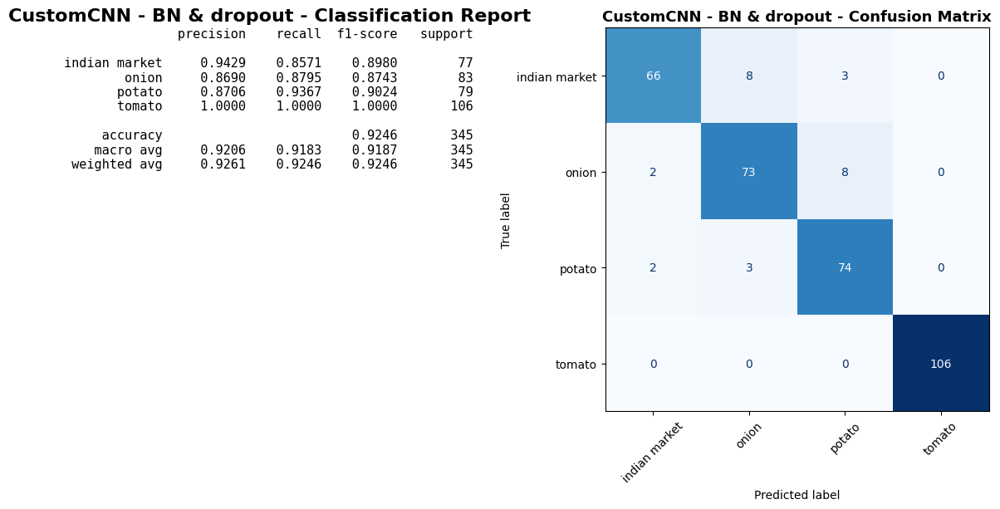

In [ ]:
cm, re = model_report(y_true["Test"], y_pred["Test"], class_names, model_name=EXP_NAME)

In [ ]:
print(re)

               precision    recall  f1-score   support

indian market     0.9429    0.8571    0.8980        77
        onion     0.8690    0.8795    0.8743        83
       potato     0.8706    0.9367    0.9024        79
       tomato     1.0000    1.0000    1.0000       106

     accuracy                         0.9246       345
    macro avg     0.9206    0.9183    0.9187       345
 weighted avg     0.9261    0.9246    0.9246       345



In [ ]:
# counts for all three splits
error_counts_summary(mis, class_names, correct=correct)

Train: 145 misclassified / 2476 images (5.86% error)
Actual                Predicted          Count  % of errors
------------------------------------------------------------
onion             ->  potato                67        46.2%
potato            ->  onion                 49        33.8%
onion             ->  indian market         19        13.1%
indian market     ->  onion                  6         4.1%
potato            ->  indian market          2         1.4%
onion             ->  tomato                 1         0.7%
indian market     ->  potato                 1         0.7%

Validation: 43 misclassified / 619 images (6.95% error)
Actual                Predicted          Count  % of errors
------------------------------------------------------------
onion             ->  potato                15        34.9%
potato            ->  onion                 15        34.9%
onion             ->  indian market          7        16.3%
indian market     ->  onion                  2  

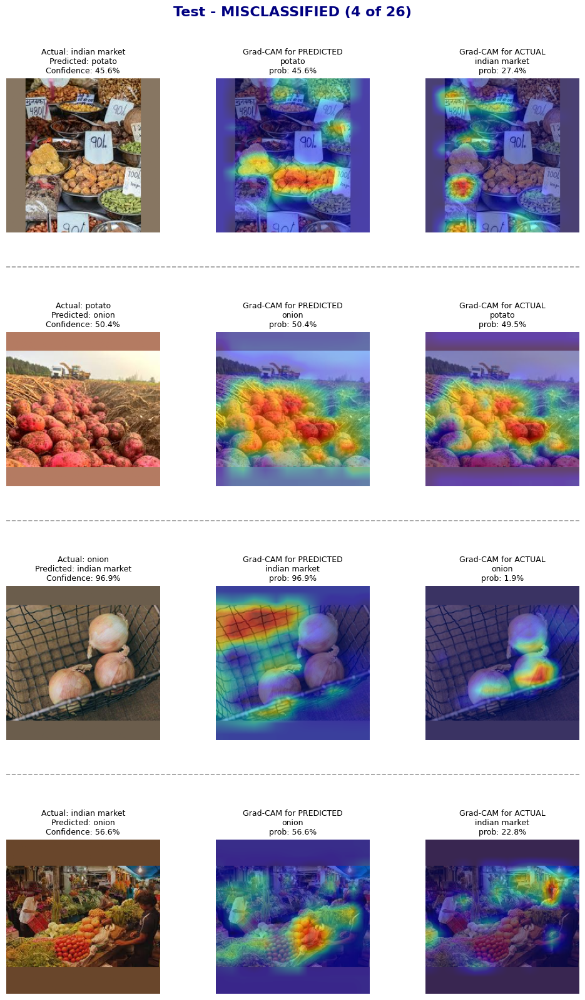

In [ ]:
show_gradcam_by_split(mis, correct, class_names, model_cnn, model_cnn.block4, mean, std,
                      splits=["Test"], show=("mis",), max_img=4, cam_for="both", order = "random", seed = 69)

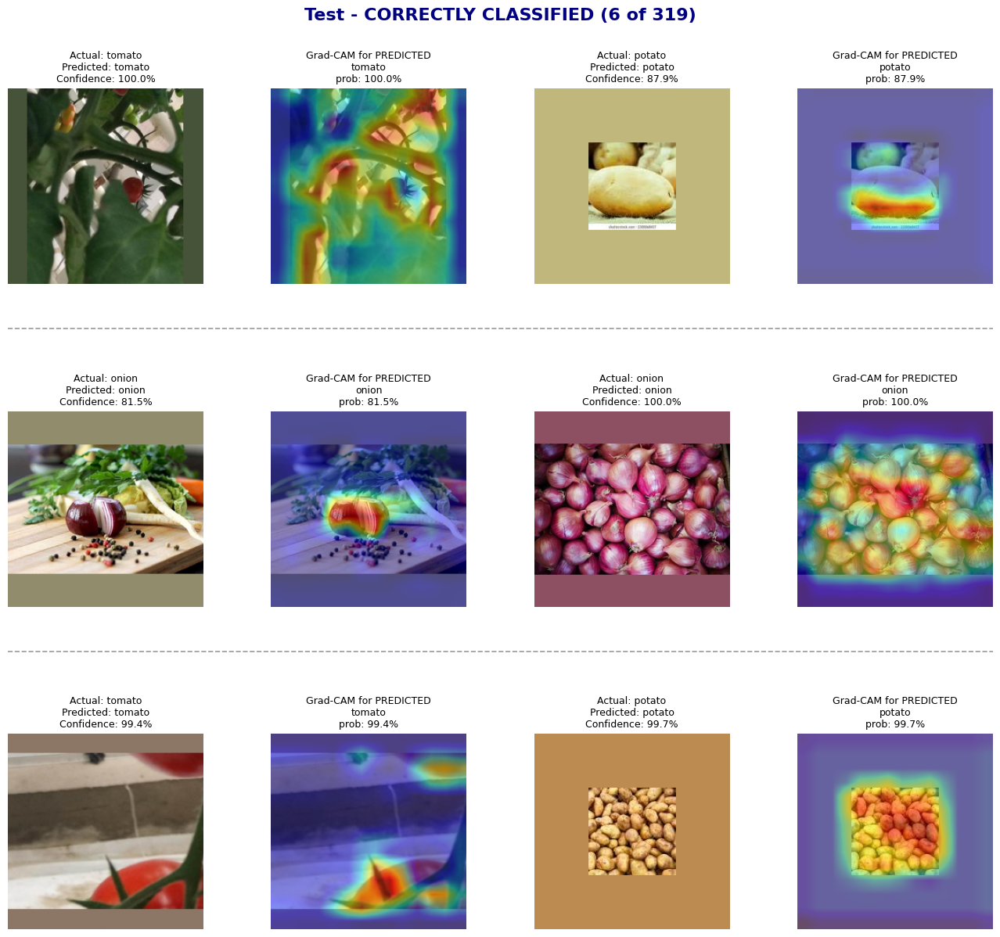

In [ ]:
show_gradcam_by_split(mis, correct, class_names, model_cnn, model_cnn.block4, mean, std,
                      splits=["Test"], show=("correct",), max_img=6, cam_for="both", order = "random")

### CustomCNN with class_weight

In [ ]:
EXP_NUM = 3
EXP_NAME = "CustomCNN - weighted"

In [ ]:
class_counts = Counter(
    train_dataset.dataset.targets[i]
    for i in train_dataset.indices
)

class_counts = [
    class_counts[i]
    for i in range(len(train_dataset.dataset.classes))
]

class_counts = torch.tensor(
    class_counts,
    dtype=torch.float32
)

class_weights = (
    class_counts.sum() / (len(class_counts) * class_counts)
).to(device)

criterion_weighted = nn.CrossEntropyLoss(
     weight=class_weights
)

print("Class weights:", class_weights)

Class weights: tensor([1.3032, 0.9116, 0.8958, 0.9810], device='cuda:0')


In [ ]:
set_seed(SEED)
train_loader, val_loader, test_loader, train_eval_loader, mean, std = get_loaders(
    base_train, train_indices, val_indices, test_dataset,
    resize_shape=RESIZE_SHAPE, imagenet_stats=False,
    seed=SEED, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)

set_seed(SEED)
model_cnn_weighted = CustomCNN(num_classes=NUM_CLASSES).to(device)

optimizer = torch.optim.AdamW(model_cnn_weighted.parameters(), lr=lr, weight_decay=weight_decay)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3, threshold=0.001, min_lr=1e-7)
scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)

history, best_model_path, best_epoch = start_training(
    model_cnn_weighted, optimizer, criterion_weighted, train_loader, val_loader, device, scaler, scheduler,
    epochs=EPOCHS, exp_num=EXP_NUM, exp_name=EXP_NAME)

Using training dataset mean, std.
mean = [0.5586165273534793, 0.4952166374869274, 0.40806714412483647]
std = [0.26263477344328234, 0.24459292432825713, 0.2638448892539471]
Classes: ['indian market', 'onion', 'potato', 'tomato']
Number of classes: 4
Train: 2476
Validation: 619
Test: 345
TensorBoard log directory: runs/3 - CustomCNN - weighted

Epoch [01/40] Train Loss: 0.6930 | Val Loss: 0.5082 | Train Acc: 71.53% | Val Acc: 81.26% | LR: 0.001000 | Time: 19.2s * BEST
Epoch [02/40] Train Loss: 0.5621 | Val Loss: 0.5071 | Train Acc: 77.22% | Val Acc: 81.10% | LR: 0.001000 | Time: 19.0s * BEST
Epoch [03/40] Train Loss: 0.5034 | Val Loss: 0.4477 | Train Acc: 80.53% | Val Acc: 80.29% | LR: 0.001000 | Time: 18.8s * BEST
Epoch [04/40] Train Loss: 0.4175 | Val Loss: 0.4929 | Train Acc: 82.71% | Val Acc: 81.58% | LR: 0.001000 | Time: 18.7s
Epoch [05/40] Train Loss: 0.4233 | Val Loss: 0.3633 | Train Acc: 82.11% | Val Acc: 84.81% | LR: 0.001000 | Time: 18.8s * BEST
Epoch [06/40] Train Loss: 0.4183

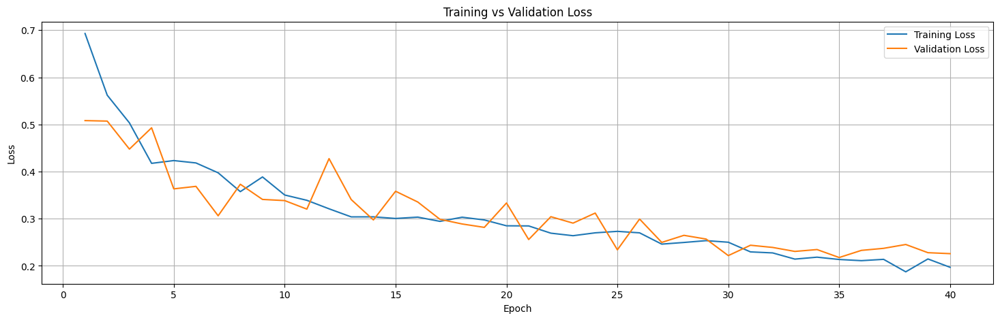

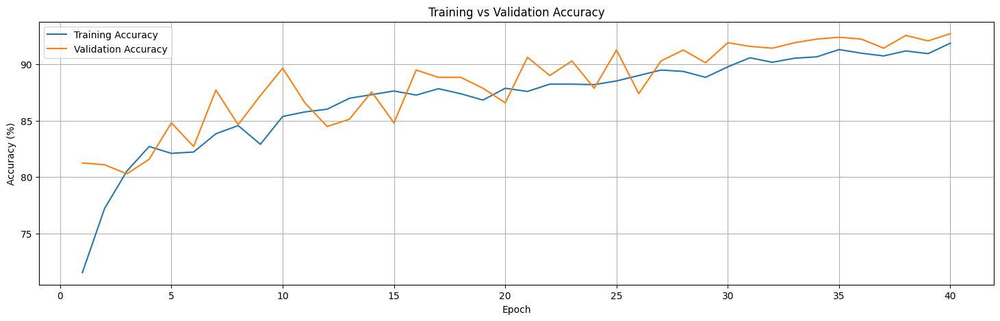

In [ ]:
plot_train_val(history)

In [ ]:
set_seed()

model_cnn_weighted = CustomCNN(
    num_classes=NUM_CLASSES
).to(device)

# if num_gpus > 1:
#     model_cnn = nn.DataParallel(model_cnn)

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True
)

model_cnn_weighted.load_state_dict(checkpoint["model_state_dict"])

<All keys matched successfully>

In [ ]:
eval_loaders = {"Train": train_eval_loader, "Validation": val_loader, "Test": test_loader}
y_true, y_pred, mis, correct = evaluate_model(model_cnn_weighted, criterion_weighted, device, eval_loaders)

# sanity checks
assert len(y_true["Train"]) == len(train_indices)
assert len(mis["Train"]) + len(correct["Train"]) == len(train_indices)

Train RESULTS
Train Loss          : 0.1457
Train Accuracy      : 94.10%
Train Misclassified : 146 / 2476

Validation RESULTS
Validation Loss          : 0.2175
Validation Accuracy      : 92.41%
Validation Misclassified : 47 / 619

Test RESULTS
Test Loss          : 0.2119
Test Accuracy      : 93.62%
Test Misclassified : 22 / 345



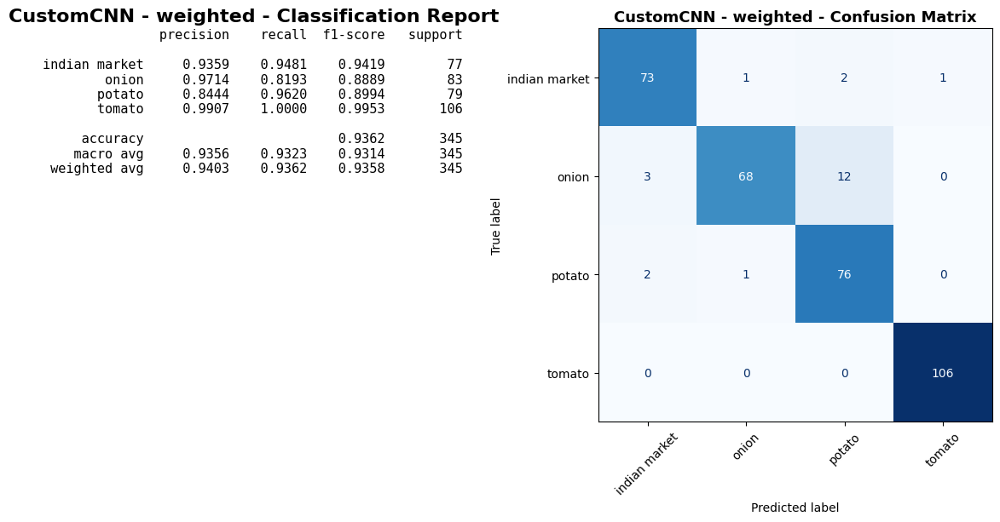

In [ ]:
cm, re = model_report(y_true["Test"], y_pred["Test"], class_names, model_name=EXP_NAME)

In [ ]:
print(re)

               precision    recall  f1-score   support

indian market     0.9359    0.9481    0.9419        77
        onion     0.9714    0.8193    0.8889        83
       potato     0.8444    0.9620    0.8994        79
       tomato     0.9907    1.0000    0.9953       106

     accuracy                         0.9362       345
    macro avg     0.9356    0.9323    0.9314       345
 weighted avg     0.9403    0.9362    0.9358       345



In [ ]:
# counts for all three splits
error_counts_summary(mis, class_names, correct=correct)

Train: 146 misclassified / 2476 images (5.90% error)
Actual                Predicted          Count  % of errors
------------------------------------------------------------
onion             ->  potato                66        45.2%
potato            ->  onion                 49        33.6%
onion             ->  indian market         22        15.1%
potato            ->  indian market          6         4.1%
indian market     ->  onion                  3         2.1%

Validation: 47 misclassified / 619 images (7.59% error)
Actual                Predicted          Count  % of errors
------------------------------------------------------------
onion             ->  potato                17        36.2%
potato            ->  onion                 16        34.0%
onion             ->  indian market          8        17.0%
indian market     ->  onion                  2         4.3%
potato            ->  indian market          2         4.3%
indian market     ->  tomato                 1  

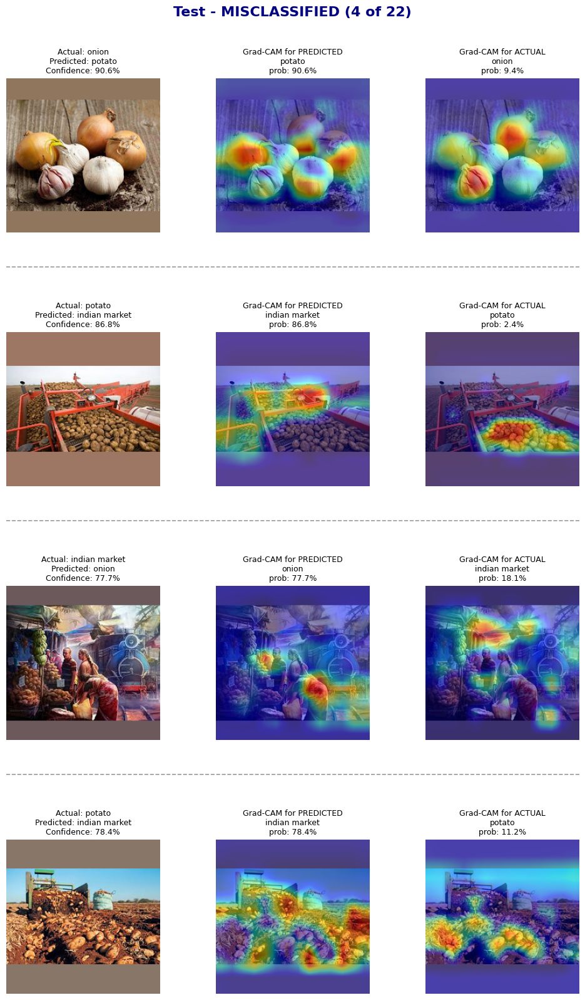

In [ ]:
show_gradcam_by_split(mis, correct, class_names, model_cnn_weighted, model_cnn_weighted.block4, mean, std,
                      splits=["Test"], show=("mis",), max_img=4, cam_for="both", order = "random", seed = 69)

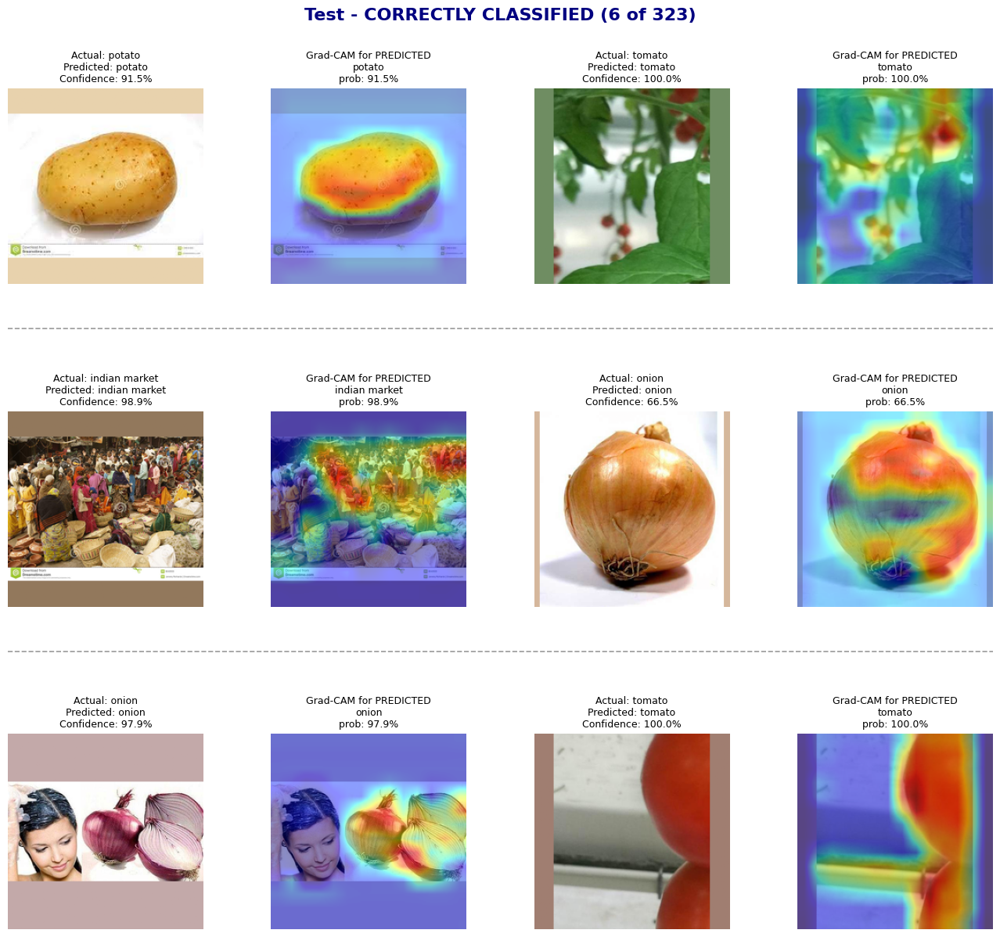

In [ ]:
show_gradcam_by_split(mis, correct, class_names, model_cnn_weighted, model_cnn_weighted.block4, mean, std,
                      splits=["Test"], show=("correct",), max_img=6, cam_for="both", order = "random")

# Transfer Learning

## VGG19 Model

In [ ]:
EXP_NUM = 4
EXP_NAME = "VGG19"

In [ ]:

assert RESIZE_SHAPE == (224, 224)   # VGG19 below relies on a 7x7 final feature map

class VGG19Model(nn.Module):
    def __init__(self, num_classes=4, pretrained=True):
        super().__init__()
        weights = models.VGG19_Weights.IMAGENET1K_V1 if pretrained else None
        self.model = models.vgg19(weights=weights)

        # For 224x224 input the last feature map is exactly 7x7, so the adaptive pool does
        # nothing. Removing it avoids its non-deterministic CUDA backward, which can raise an
        # error under torch.use_deterministic_algorithms(True), thats why converting to a Indentity.
        self.model.avgpool = nn.Identity()

        # classifier already has two Dropout(0.5) layers; only replace the last Linear
        in_features = self.model.classifier[6].in_features      # 4096
        self.model.classifier[6] = nn.Linear(in_features, num_classes)

    def forward(self, x):
        return self.model(x)

summary(VGG19Model(NUM_CLASSES).to(device), input_size=(1, 3, *RESIZE_SHAPE))

Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:02<00:00, 230MB/s]  


Layer (type:depth-idx)                   Output Shape              Param #
VGG19Model                               [1, 4]                    --
├─VGG: 1-1                               [1, 4]                    --
│    └─Sequential: 2-1                   [1, 512, 7, 7]            --
│    │    └─Conv2d: 3-1                  [1, 64, 224, 224]         1,792
│    │    └─ReLU: 3-2                    [1, 64, 224, 224]         --
│    │    └─Conv2d: 3-3                  [1, 64, 224, 224]         36,928
│    │    └─ReLU: 3-4                    [1, 64, 224, 224]         --
│    │    └─MaxPool2d: 3-5               [1, 64, 112, 112]         --
│    │    └─Conv2d: 3-6                  [1, 128, 112, 112]        73,856
│    │    └─ReLU: 3-7                    [1, 128, 112, 112]        --
│    │    └─Conv2d: 3-8                  [1, 128, 112, 112]        147,584
│    │    └─ReLU: 3-9                    [1, 128, 112, 112]        --
│    │    └─MaxPool2d: 3-10              [1, 128, 56, 56]          --

In [ ]:
set_seed(SEED)
train_loader, val_loader, test_loader, train_eval_loader, mean, std = get_loaders(
    base_train, train_indices, val_indices, test_dataset,
    resize_shape=RESIZE_SHAPE, imagenet_stats=True,
    seed=SEED, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)

set_seed(SEED)
model_vgg19 = VGG19Model(num_classes=NUM_CLASSES, pretrained=True).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model_vgg19.parameters(), lr=0.001, weight_decay=0.0001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3, threshold=0.001, min_lr=1e-7)
scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)

history, best_model_path, best_epoch = start_training(
    model_vgg19, optimizer, criterion, train_loader, val_loader, device, scaler, scheduler,
    epochs=EPOCHS, exp_num=EXP_NUM, exp_name=EXP_NAME, patience=10, max_loss_gap = 0.1)

Using ImageNet mean, std.
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]
Classes: ['indian market', 'onion', 'potato', 'tomato']
Number of classes: 4
Train: 2476
Validation: 619
Test: 345
TensorBoard log directory: runs/4 - VGG19

Epoch [01/40] Train Loss: 1.6438 | Val Loss: 0.9540 | Train Acc: 34.85% | Val Acc: 51.53% | LR: 0.001000 | Time: 32.6s * BEST
Epoch [02/40] Train Loss: 1.1200 | Val Loss: 0.7731 | Train Acc: 47.78% | Val Acc: 65.11% | LR: 0.001000 | Time: 33.2s * BEST
Epoch [03/40] Train Loss: 0.7801 | Val Loss: 0.6014 | Train Acc: 62.12% | Val Acc: 75.28% | LR: 0.001000 | Time: 32.6s * BEST
Epoch [04/40] Train Loss: 0.6747 | Val Loss: 0.5328 | Train Acc: 70.84% | Val Acc: 77.06% | LR: 0.001000 | Time: 32.8s * BEST
Epoch [05/40] Train Loss: 0.5768 | Val Loss: 1.7865 | Train Acc: 74.15% | Val Acc: 54.60% | LR: 0.001000 | Time: 30.0s
Epoch [06/40] Train Loss: 0.6546 | Val Loss: 0.5804 | Train Acc: 71.49% | Val Acc: 72.70% | LR: 0.001000 | Time: 29.7s
Epoch [07/40] Tra

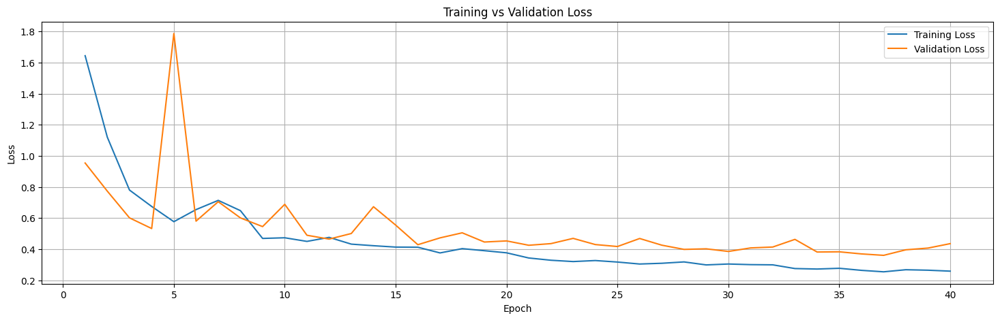

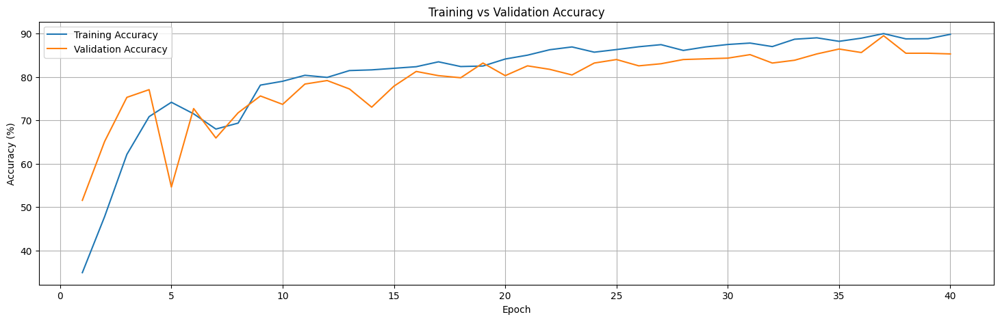

In [ ]:
plot_train_val(history)

In [ ]:
set_seed()

model_vgg19 = VGG19Model(
    num_classes=NUM_CLASSES,
    pretrained=False
).to(device)

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True
)

model_vgg19.load_state_dict(checkpoint["model_state_dict"])

<All keys matched successfully>

In [ ]:
eval_loaders = {"Train": train_eval_loader, "Validation": val_loader, "Test": test_loader}
y_true, y_pred, mis, correct = evaluate_model(model_vgg19, criterion, device, eval_loaders)

# sanity checks
assert len(y_true["Train"]) == len(train_indices)
assert len(mis["Train"]) + len(correct["Train"]) == len(train_indices)

Train RESULTS
Train Loss          : 0.2779
Train Accuracy      : 88.33%
Train Misclassified : 289 / 2476

Validation RESULTS
Validation Loss          : 0.3855
Validation Accuracy      : 84.33%
Validation Misclassified : 97 / 619

Test RESULTS
Test Loss          : 0.4027
Test Accuracy      : 80.87%
Test Misclassified : 66 / 345



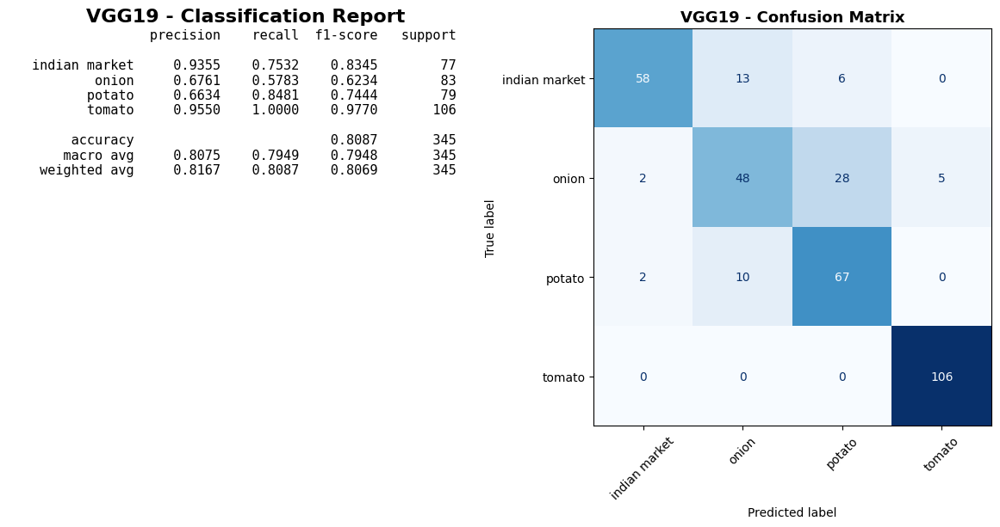

In [ ]:
cm, re = model_report(y_true["Test"], y_pred["Test"], class_names, model_name="VGG19")

In [ ]:
print(re)

               precision    recall  f1-score   support

indian market     0.9355    0.7532    0.8345        77
        onion     0.6761    0.5783    0.6234        83
       potato     0.6634    0.8481    0.7444        79
       tomato     0.9550    1.0000    0.9770       106

     accuracy                         0.8087       345
    macro avg     0.8075    0.7949    0.7948       345
 weighted avg     0.8167    0.8087    0.8069       345



In [ ]:
# counts for all three splits
error_counts_summary(mis, class_names, correct=correct)

Train: 289 misclassified / 2476 images (11.67% error)
Actual                Predicted          Count  % of errors
------------------------------------------------------------
onion             ->  potato               155        53.6%
potato            ->  onion                 63        21.8%
indian market     ->  onion                 24         8.3%
onion             ->  indian market         19         6.6%
onion             ->  tomato                13         4.5%
indian market     ->  potato                 8         2.8%
potato            ->  indian market          6         2.1%
indian market     ->  tomato                 1         0.3%

Validation: 97 misclassified / 619 images (15.67% error)
Actual                Predicted          Count  % of errors
------------------------------------------------------------
onion             ->  potato                45        46.4%
potato            ->  onion                 19        19.6%
indian market     ->  onion                 11

## MobileNet Model

In [ ]:
EXP_NUM = 5
EXP_NAME = "MobileNetV2"

In [ ]:
class MobileNetV2Model(nn.Module):
    def __init__(self, num_classes=4, dropout=0.3, pretrained=True):
        super().__init__()
        weights = models.MobileNet_V2_Weights.IMAGENET1K_V1 if pretrained else None
        self.model = models.mobilenet_v2(weights=weights)
        in_features = self.model.classifier[1].in_features      # 1280
        self.model.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        return self.model(x)

summary(MobileNetV2Model(NUM_CLASSES).to(device), input_size=(1, 3, *RESIZE_SHAPE))

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 127MB/s]


Layer (type:depth-idx)                                  Output Shape              Param #
MobileNetV2Model                                        [1, 4]                    --
├─MobileNetV2: 1-1                                      [1, 4]                    --
│    └─Sequential: 2-1                                  [1, 1280, 7, 7]           --
│    │    └─Conv2dNormActivation: 3-1                   [1, 32, 112, 112]         928
│    │    └─InvertedResidual: 3-2                       [1, 16, 112, 112]         896
│    │    └─InvertedResidual: 3-3                       [1, 24, 56, 56]           5,136
│    │    └─InvertedResidual: 3-4                       [1, 24, 56, 56]           8,832
│    │    └─InvertedResidual: 3-5                       [1, 32, 28, 28]           10,000
│    │    └─InvertedResidual: 3-6                       [1, 32, 28, 28]           14,848
│    │    └─InvertedResidual: 3-7                       [1, 32, 28, 28]           14,848
│    │    └─InvertedResidual: 3-8       

In [ ]:
set_seed(SEED)
train_loader, val_loader, test_loader, train_eval_loader, mean, std = get_loaders(
    base_train, train_indices, val_indices, test_dataset,
    resize_shape=RESIZE_SHAPE, imagenet_stats=True,
    seed=SEED, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)

set_seed(SEED)
model_mobilenetv2 = MobileNetV2Model(num_classes=NUM_CLASSES, dropout=0.3, pretrained=True).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model_mobilenetv2.parameters(), lr=0.001, weight_decay=0.0001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3, threshold=0.001, min_lr=1e-7)
scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)

history, best_model_path, best_epoch = start_training(
    model_mobilenetv2, optimizer, criterion, train_loader, val_loader, device, scaler, scheduler,
    epochs=EPOCHS, exp_num=EXP_NUM, exp_name=EXP_NAME, patience=7, max_loss_gap = 0.01)

Using ImageNet mean, std.
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]
Classes: ['indian market', 'onion', 'potato', 'tomato']
Number of classes: 4
Train: 2476
Validation: 619
Test: 345
TensorBoard log directory: runs/5 - MobileNetV2

Epoch [01/40] Train Loss: 0.3549 | Val Loss: 0.1928 | Train Acc: 87.28% | Val Acc: 94.83% | LR: 0.001000 | Time: 19.6s * BEST
Epoch [02/40] Train Loss: 0.2329 | Val Loss: 0.1101 | Train Acc: 92.45% | Val Acc: 95.64% | LR: 0.001000 | Time: 19.3s * BEST
Epoch [03/40] Train Loss: 0.1666 | Val Loss: 0.1009 | Train Acc: 93.46% | Val Acc: 96.12% | LR: 0.001000 | Time: 18.8s * BEST
Epoch [04/40] Train Loss: 0.1487 | Val Loss: 0.1943 | Train Acc: 94.91% | Val Acc: 93.54% | LR: 0.001000 | Time: 19.1s
Epoch [05/40] Train Loss: 0.1196 | Val Loss: 0.1138 | Train Acc: 95.96% | Val Acc: 94.99% | LR: 0.001000 | Time: 19.0s
Epoch [06/40] Train Loss: 0.1684 | Val Loss: 0.1203 | Train Acc: 94.47% | Val Acc: 94.83% | LR: 0.001000 | Time: 18.8s
Epoch [07/40] Trai

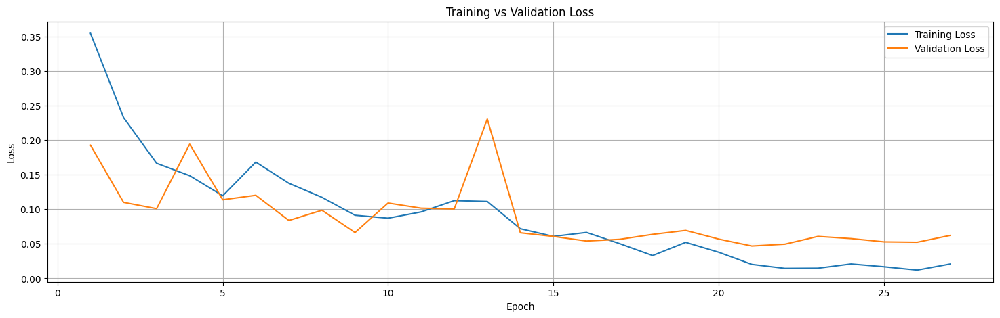

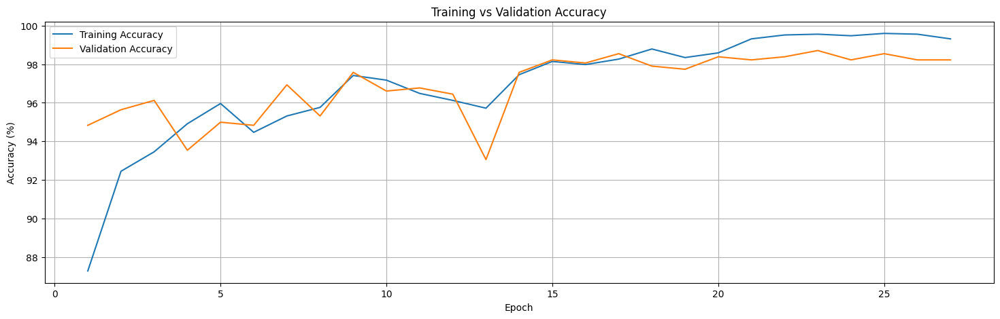

In [ ]:
plot_train_val(history)

In [ ]:
set_seed()

model_mobilenetv2 = MobileNetV2Model(
    num_classes=NUM_CLASSES,
    dropout=0.3,
    pretrained=False
).to(device)

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True
)

model_mobilenetv2.load_state_dict(checkpoint["model_state_dict"])

<All keys matched successfully>

In [ ]:
eval_loaders = {"Train": train_eval_loader, "Validation": val_loader, "Test": test_loader}
y_true, y_pred, mis, correct = evaluate_model(model_mobilenetv2, criterion, device, eval_loaders)

# sanity checks
assert len(y_true["Train"]) == len(train_indices)
assert len(mis["Train"]) + len(correct["Train"]) == len(train_indices)

Train RESULTS
Train Loss          : 0.0111
Train Accuracy      : 99.76%
Train Misclassified : 6 / 2476

Validation RESULTS
Validation Loss          : 0.0542
Validation Accuracy      : 98.06%
Validation Misclassified : 12 / 619

Test RESULTS
Test Loss          : 0.1646
Test Accuracy      : 95.65%
Test Misclassified : 15 / 345



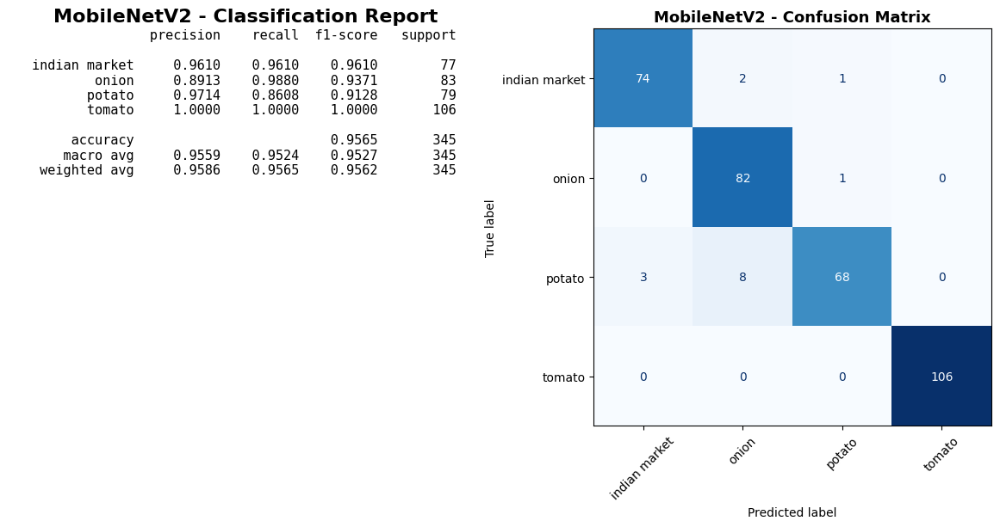

In [ ]:
cm, re = model_report(y_true["Test"], y_pred["Test"], class_names, model_name=EXP_NAME)

In [ ]:
print(re)

               precision    recall  f1-score   support

indian market     0.9610    0.9610    0.9610        77
        onion     0.8913    0.9880    0.9371        83
       potato     0.9714    0.8608    0.9128        79
       tomato     1.0000    1.0000    1.0000       106

     accuracy                         0.9565       345
    macro avg     0.9559    0.9524    0.9527       345
 weighted avg     0.9586    0.9565    0.9562       345



In [ ]:
# counts for all three splits
error_counts_summary(mis, class_names, correct=correct)

Train: 6 misclassified / 2476 images (0.24% error)
Actual                Predicted          Count  % of errors
------------------------------------------------------------
onion             ->  potato                 3        50.0%
potato            ->  indian market          1        16.7%
indian market     ->  onion                  1        16.7%
potato            ->  onion                  1        16.7%

Validation: 12 misclassified / 619 images (1.94% error)
Actual                Predicted          Count  % of errors
------------------------------------------------------------
potato            ->  onion                  5        41.7%
onion             ->  potato                 3        25.0%
onion             ->  indian market          2        16.7%
indian market     ->  onion                  1         8.3%
onion             ->  tomato                 1         8.3%

Test: 15 misclassified / 345 images (4.35% error)
Actual                Predicted          Count  % of errors

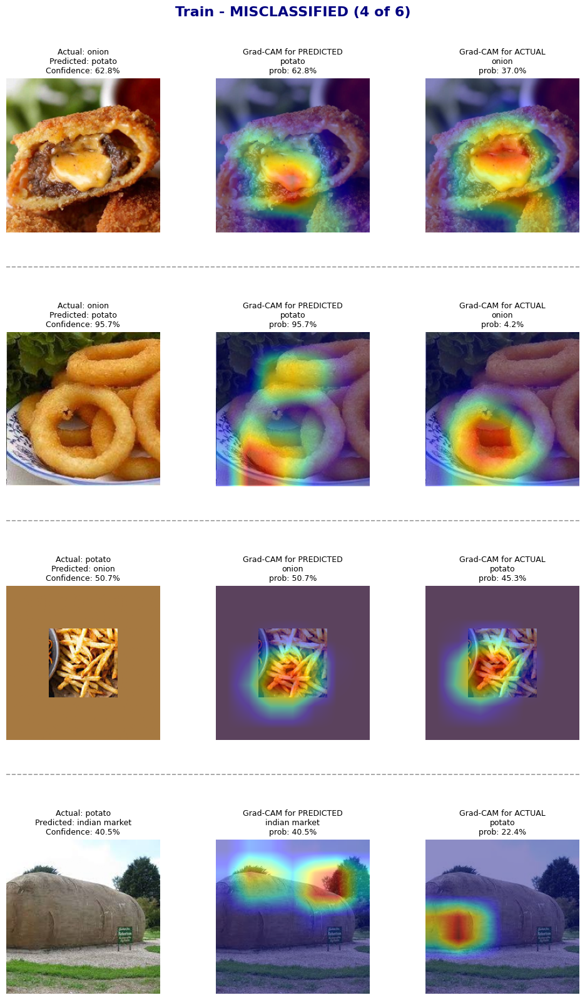

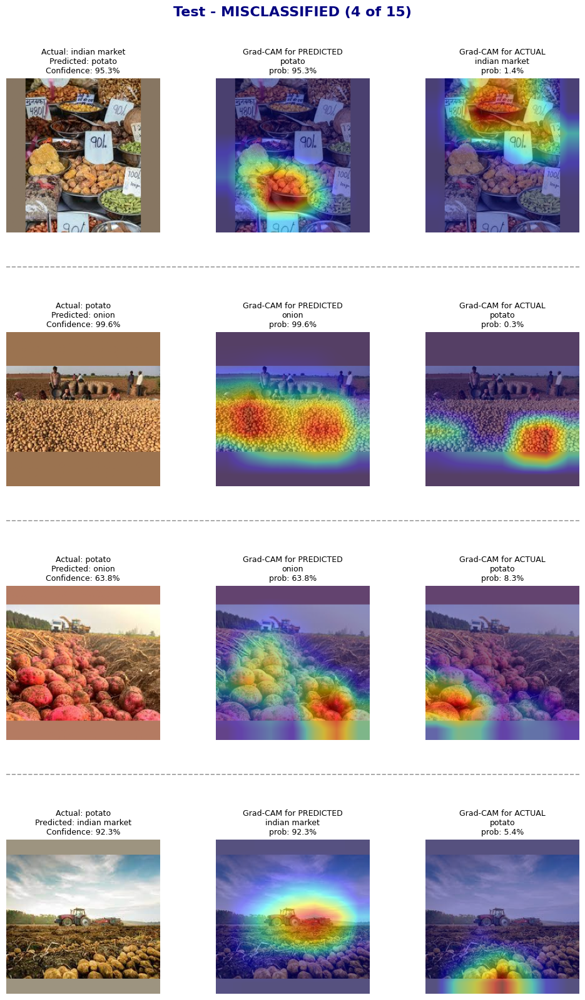

In [ ]:
show_gradcam_by_split(mis, correct, class_names, model_mobilenetv2, model_mobilenetv2.model.features[-1], mean, std,
                      splits=["Train", "Test"], show=("mis",), max_img=4, cam_for="both", order = "random", seed = 34)

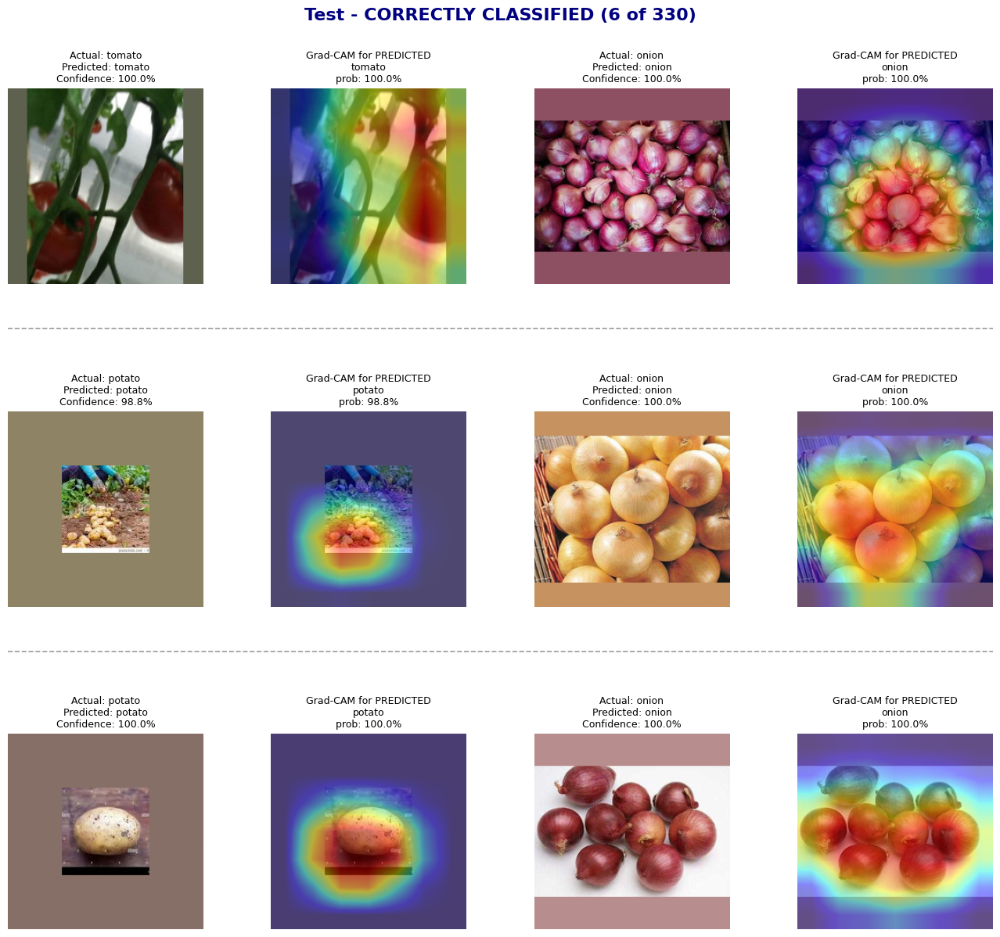

In [ ]:
show_gradcam_by_split(mis, correct, class_names, model_mobilenetv2, model_mobilenetv2.model.features[-1], mean, std,
                      splits=["Test"], show=("correct",), max_img=6, cam_for="both", order = "random")

## ResNet50 Model

In [ ]:
EXP_NUM = 6
EXP_NAME = "ResNet50"

In [ ]:
class ResNet50Model(nn.Module):
    def __init__(self, num_classes=4, dropout=0.3, pretrained=True):
        super().__init__()
        weights = models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
        self.model = models.resnet50(weights=weights)
        in_features = self.model.fc.in_features
        self.model.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_features, num_classes))

    def forward(self, x):
        return self.model(x)

summary(ResNet50Model(NUM_CLASSES).to(device), input_size=(1, 3, *RESIZE_SHAPE))

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 200MB/s]


Layer (type:depth-idx)                        Output Shape              Param #
ResNet50Model                                 [1, 4]                    --
├─ResNet: 1-1                                 [1, 4]                    --
│    └─Conv2d: 2-1                            [1, 64, 112, 112]         9,408
│    └─BatchNorm2d: 2-2                       [1, 64, 112, 112]         128
│    └─ReLU: 2-3                              [1, 64, 112, 112]         --
│    └─MaxPool2d: 2-4                         [1, 64, 56, 56]           --
│    └─Sequential: 2-5                        [1, 256, 56, 56]          --
│    │    └─Bottleneck: 3-1                   [1, 256, 56, 56]          75,008
│    │    └─Bottleneck: 3-2                   [1, 256, 56, 56]          70,400
│    │    └─Bottleneck: 3-3                   [1, 256, 56, 56]          70,400
│    └─Sequential: 2-6                        [1, 512, 28, 28]          --
│    │    └─Bottleneck: 3-4                   [1, 512, 28, 28]          379,392

In [ ]:
set_seed(SEED)
train_loader, val_loader, test_loader, train_eval_loader, mean, std = get_loaders(
    base_train, train_indices, val_indices, test_dataset,
    resize_shape=RESIZE_SHAPE, imagenet_stats=True,
    seed=SEED, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)

set_seed(SEED)
model_resnet50 = ResNet50Model(num_classes=NUM_CLASSES, dropout=0.3, pretrained=True).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model_resnet50.parameters(), lr=0.001, weight_decay=0.0001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3, threshold=0.001, min_lr=1e-7)
scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)

history, best_model_path, best_epoch = start_training(
    model_resnet50, optimizer, criterion, train_loader, val_loader, device, scaler, scheduler,
    epochs=EPOCHS, exp_num=EXP_NUM, exp_name=EXP_NAME, patience=7, max_loss_gap = 0.01)

Using ImageNet mean, std.
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]
Classes: ['indian market', 'onion', 'potato', 'tomato']
Number of classes: 4
Train: 2476
Validation: 619
Test: 345
TensorBoard log directory: runs/6 - ResNet50

Epoch [01/40] Train Loss: 0.5678 | Val Loss: 0.5598 | Train Acc: 79.73% | Val Acc: 79.00% | LR: 0.001000 | Time: 21.0s * BEST
Epoch [02/40] Train Loss: 0.4006 | Val Loss: 0.4277 | Train Acc: 85.38% | Val Acc: 84.98% | LR: 0.001000 | Time: 19.8s (SKIPPED: val_loss improved but, gap exceeded max_loss_gap)
Epoch [03/40] Train Loss: 0.3037 | Val Loss: 0.2783 | Train Acc: 88.93% | Val Acc: 91.60% | LR: 0.001000 | Time: 20.2s * BEST
Epoch [04/40] Train Loss: 0.2602 | Val Loss: 0.4834 | Train Acc: 89.94% | Val Acc: 79.00% | LR: 0.001000 | Time: 19.7s
Epoch [05/40] Train Loss: 0.2220 | Val Loss: 0.1894 | Train Acc: 91.76% | Val Acc: 93.54% | LR: 0.001000 | Time: 20.3s * BEST
Epoch [06/40] Train Loss: 0.2406 | Val Loss: 0.3178 | Train Acc: 91.03% | Val Ac

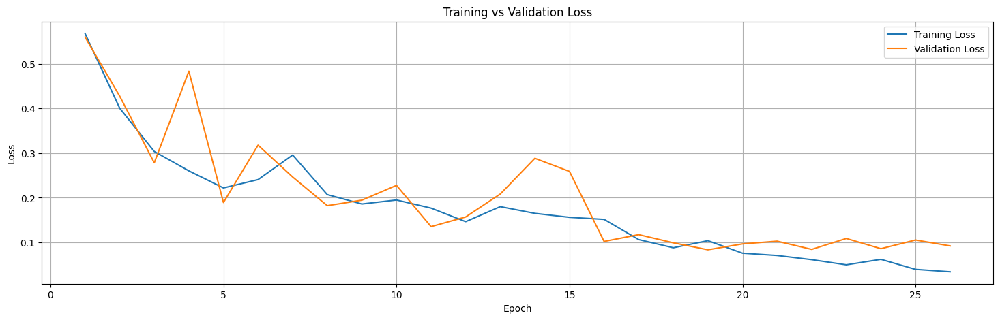

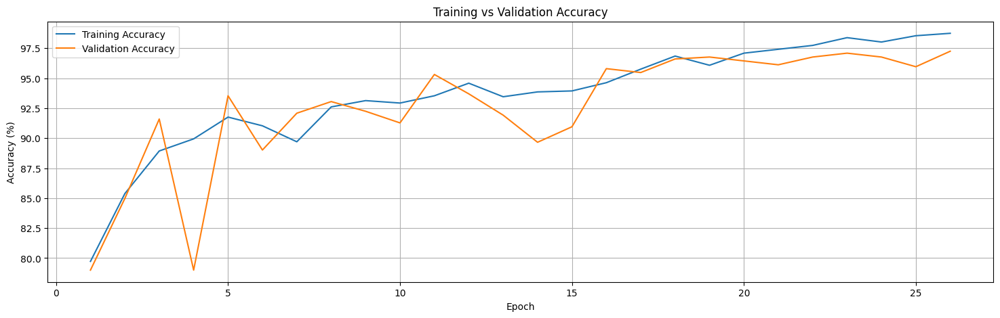

In [ ]:
plot_train_val(history)

In [ ]:
set_seed()

model_resnet50 = ResNet50Model(
    num_classes=NUM_CLASSES,
    dropout=0.3,
    pretrained=False
).to(device)

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True
)

model_resnet50.load_state_dict(checkpoint["model_state_dict"])

<All keys matched successfully>

In [ ]:
eval_loaders = {"Train": train_eval_loader, "Validation": val_loader, "Test": test_loader}
y_true, y_pred, mis, correct = evaluate_model(model_resnet50, criterion, device, eval_loaders)

# sanity checks
assert len(y_true["Train"]) == len(train_indices)
assert len(mis["Train"]) + len(correct["Train"]) == len(train_indices)

Train RESULTS
Train Loss          : 0.0249
Train Accuracy      : 99.39%
Train Misclassified : 15 / 2476

Validation RESULTS
Validation Loss          : 0.0835
Validation Accuracy      : 96.77%
Validation Misclassified : 20 / 619

Test RESULTS
Test Loss          : 0.0968
Test Accuracy      : 96.23%
Test Misclassified : 13 / 345



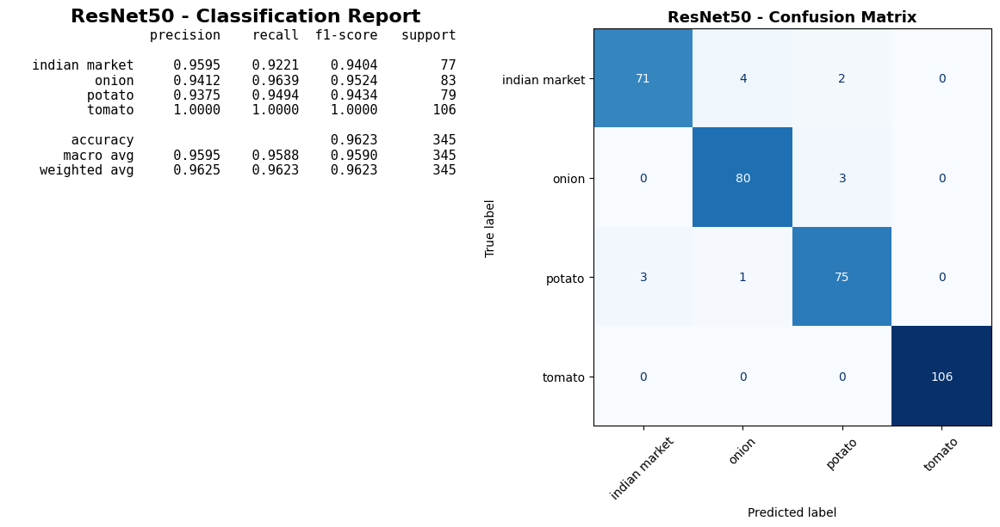

In [ ]:
cm, re = model_report(y_true["Test"], y_pred["Test"], class_names, model_name=EXP_NAME)

In [ ]:
print(re)

               precision    recall  f1-score   support

indian market     0.9595    0.9221    0.9404        77
        onion     0.9412    0.9639    0.9524        83
       potato     0.9375    0.9494    0.9434        79
       tomato     1.0000    1.0000    1.0000       106

     accuracy                         0.9623       345
    macro avg     0.9595    0.9588    0.9590       345
 weighted avg     0.9625    0.9623    0.9623       345



In [ ]:
# counts for all three splits
error_counts_summary(mis, class_names, correct=correct)

Train: 15 misclassified / 2476 images (0.61% error)
Actual                Predicted          Count  % of errors
------------------------------------------------------------
onion             ->  potato                12        80.0%
potato            ->  onion                  2        13.3%
indian market     ->  onion                  1         6.7%

Validation: 20 misclassified / 619 images (3.23% error)
Actual                Predicted          Count  % of errors
------------------------------------------------------------
onion             ->  potato                 8        40.0%
potato            ->  onion                  6        30.0%
indian market     ->  onion                  2        10.0%
onion             ->  indian market          2        10.0%
indian market     ->  potato                 1         5.0%
potato            ->  indian market          1         5.0%

Test: 13 misclassified / 345 images (3.77% error)
Actual                Predicted          Count  % of error

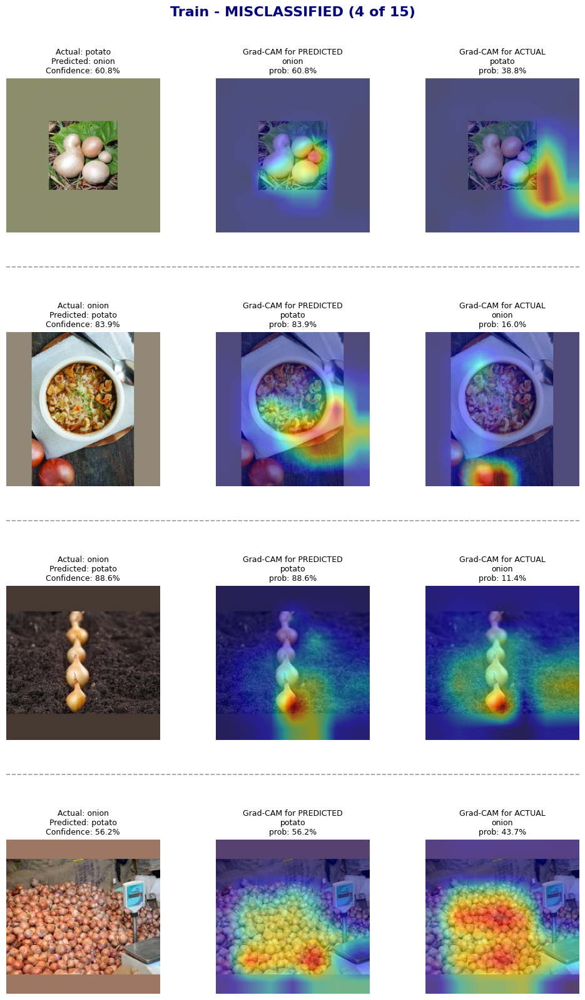

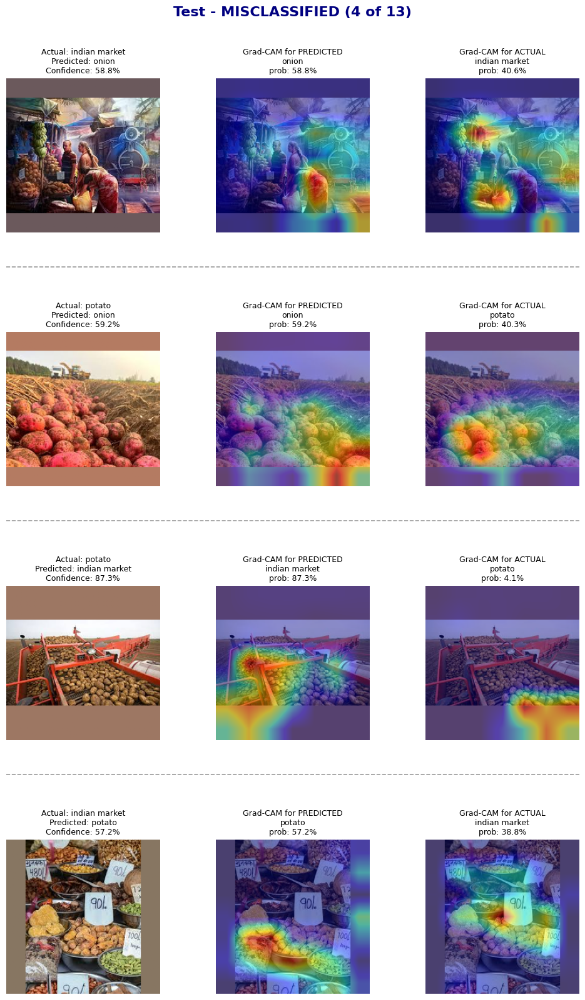

In [ ]:
show_gradcam_by_split(mis, correct, class_names, model_resnet50, model_resnet50.model.layer4[-1], mean, std,
                      splits=["Train", "Test"], show=("mis",), max_img=4, cam_for="both", order = "random", seed = 33)

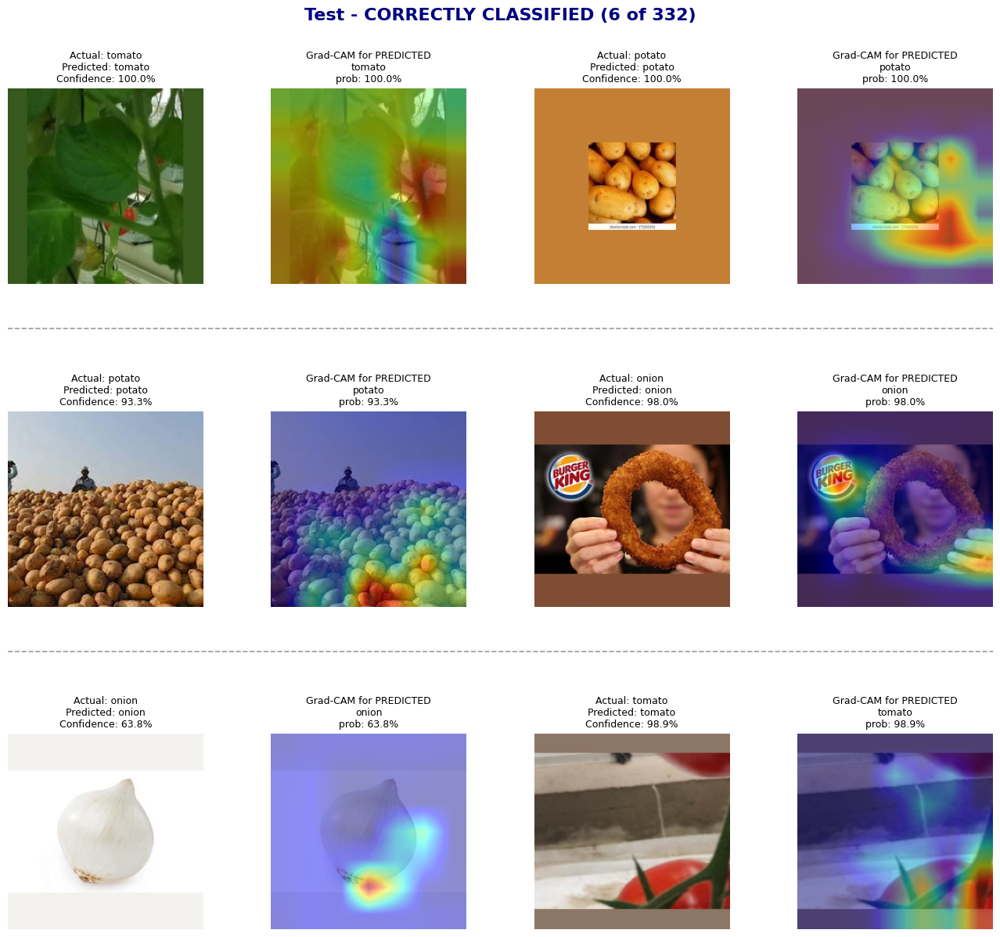

In [ ]:
show_gradcam_by_split(mis, correct, class_names, model_resnet50, model_resnet50.model.layer4[-1], mean, std,
                      splits=["Test"], show=("correct",), max_img=6, cam_for="both", order = "random", seed = 21)

# Fine-tuning

## Fine-tuning Setup

All models start from **ImageNet weights**, with a new 4-class head. Training is gradual, in 3 stages (max 8 + 8 + 10 epochs). Frozen layers keep their ImageNet weights, and their BatchNorm statistics stay fixed.

```
ImageNet weights ─► new 4-class head ─► Stage 1 ─────► Stage 2 ──────────► Stage 3
                                        head only      head + top block    all layers
```

| Stage | Trained layers | Purpose |
|---|---|---|
| 1 | Head only | Train the new classifier on frozen features |
| 2 | Head + top block | Adapt the highest-level features |
| 3 | All layers, discriminative LRs | Fine-tune the full network (lower LR for earlier layers) |

### VGG19
| Stage | Trainable layers (LR) |
|---|---|
| 1 | classifier (1e-4) |
| 2 | classifier (5e-5) + block5 `features[28:]` (1e-5) |
| 3 | classifier (2e-5), block5 (1e-5), block4 `[19:28]` (5e-6), block3 `[10:19]` (2.5e-6), block2 `[5:10]` (1e-6), block1 `[:5]` (1e-6) |

### MobileNetV2
| Stage | Trainable layers (LR) |
|---|---|
| 1 | classifier (1e-3) |
| 2 | classifier (2e-4) + top `features[14:]` (5e-5) |
| 3 | classifier (5e-5), top (2.5e-5), mid `features[7:14]` (1e-5), low `features[:7]` (5e-6) |

### ResNet-50
| Stage | Trainable layers (LR) |
|---|---|
| 1 | `fc` (1e-3) |
| 2 | `fc` (2e-4) + `layer4` (5e-5) |
| 3 | `fc` (5e-5), `layer4` (2.5e-5), `layer3` (1e-5), `layer2` (5e-6), `conv1` + `bn1` + `layer1` (5e-6) |

Optimizer: AdamW (weight decay 2e-4), `ReduceLROnPlateau` on validation loss, best checkpoint chosen by lowest validation loss.

In [ ]:
import contextlib, io
from torch.nn.modules.batchnorm import _BatchNorm

FT_DIR = "finetuning"


# ---------- registry: everything model-specific lives here ----------
# groups: ordered parts of the network (head first, then deep -> shallow)
# stages: which groups train in each stage, with their learning rates
ARCHS = {
    "vgg19": dict(
        build=lambda pretrained=False: VGG19Model(NUM_CLASSES, pretrained=pretrained),
        groups=lambda m: {
            "head":   m.model.classifier,
            "block5": m.model.features[28:],
            "block4": m.model.features[19:28],
            "block3": m.model.features[10:19],
            "block2": m.model.features[5:10],
            "block1": m.model.features[:5],
        },
        gradcam_layer=lambda m: m.model.features[35],        # last ReLU of conv5_4
        full_lr=1e-5,                                        # for the all-at-once variant
        stages=[
            dict(name="stage1", epochs=8,  plateau=1, lrs={"head": 1e-4}),
            dict(name="stage2", epochs=8,  plateau=1, lrs={"head": 5e-5, "block5": 1e-5}),
            dict(name="stage3", epochs=10, plateau=2,
                 lrs={"head": 2e-5, "block5": 1e-5, "block4": 5e-6,
                      "block3": 2.5e-6, "block2": 1e-6, "block1": 1e-6}),
        ],
    ),
    "mobilenetv2": dict(
        build=lambda pretrained=False: MobileNetV2Model(NUM_CLASSES, pretrained=pretrained),
        groups=lambda m: {
            "head": m.model.classifier,
            "top":  m.model.features[14:],
            "mid":  m.model.features[7:14],
            "low":  m.model.features[:7],
        },
        gradcam_layer=lambda m: m.model.features[-1],
        full_lr=1e-4,
        stages=[
            dict(name="stage1", epochs=8,  plateau=1, lrs={"head": 1e-3}),
            dict(name="stage2", epochs=8,  plateau=1, lrs={"head": 2e-4, "top": 5e-5}),
            dict(name="stage3", epochs=10, plateau=2,
                 lrs={"head": 5e-5, "top": 2.5e-5, "mid": 1e-5, "low": 5e-6}),
        ],
    ),
    "resnet50": dict(
        build=lambda pretrained=False: ResNet50Model(NUM_CLASSES, pretrained=pretrained),
        groups=lambda m: {
            "head":   m.model.fc,
            "layer4": m.model.layer4,
            "layer3": m.model.layer3,
            "layer2": m.model.layer2,
            "early":  nn.Sequential(m.model.conv1, m.model.bn1, m.model.layer1),
        },
        gradcam_layer=lambda m: m.model.layer4,
        full_lr=1e-4,
        stages=[
            dict(name="stage1", epochs=8,  plateau=1, lrs={"head": 1e-3}),
            dict(name="stage2", epochs=8,  plateau=1, lrs={"head": 2e-4, "layer4": 5e-5}),
            dict(name="stage3", epochs=10, plateau=2,
                 lrs={"head": 5e-5, "layer4": 2.5e-5, "layer3": 1e-5, "layer2": 5e-6, "early": 5e-6}),
        ],
    ),
}


# ---------- generic helpers (work for every entry above) ----------
def load_model(arch, ckpt="imagenet"):
    """ckpt = "imagenet" for pretrained weights, or a path to own checkpoint."""
    spec = ARCHS[arch]
    if ckpt == "imagenet":
        model = spec["build"](pretrained=True)
    else:
        model = spec["build"](pretrained=False)
        model.load_state_dict(torch.load(ckpt, map_location="cpu", weights_only=True)["model_state_dict"])
    return model.to(device)


def check_groups(model, groups):
    ids = [id(p) for g in groups.values() for p in g.parameters()]
    assert len(ids) == len(set(ids)), "a parameter appears in two groups"
    missing = [n for n, p in model.named_parameters() if id(p) not in set(ids)]
    assert not missing, f"parameters not in any group: {missing[:5]}"


def _bn_to_eval(module, inputs):          # forward pre-hook; must return None
    module.eval()


def set_trainable(model, groups, lrs, freeze_bn_stats=True):
    """Freeze everything, unfreeze the groups in `lrs`, return optimizer param groups.
    freeze_bn_stats=True: BatchNorm layers in frozen groups keep their running statistics."""
    unknown = set(lrs) - set(groups)
    assert not unknown, f"unknown groups: {unknown}"

    for h in getattr(model, "_bn_hooks", []):          # drop hooks from the previous stage
        h.remove()
    model._bn_hooks = []

    for p in model.parameters():
        p.requires_grad = False

    param_groups = []
    for name, module in groups.items():
        if name in lrs:
            params = list(module.parameters())
            for p in params:
                p.requires_grad = True
            param_groups.append({"params": params, "lr": lrs[name], "name": name})
        elif freeze_bn_stats:
            for sub in module.modules():
                if isinstance(sub, _BatchNorm):
                    model._bn_hooks.append(sub.register_forward_pre_hook(_bn_to_eval))
    return param_groups


def finetune_stage(model, train_loader, val_loader, optimizer, scheduler, criterion,
                   stage_name, epochs, patience, ckpt_dir, seed, exp_num):
    set_seed(seed)
    writer = start_experiment(exp_num, stage_name)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
    best_path = os.path.join(ckpt_dir, f"{stage_name}_best.pth")
    best_val_loss, best_epoch, bad = float("inf"), 0, 0
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device, scaler)
        va_loss, va_acc = validate_one_epoch(model, val_loader, criterion, device)
        scheduler.step(va_loss)

        for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)):
            history[k].append(v)

        writer.add_scalar("Loss/Train", tr_loss, epoch + 1)
        writer.add_scalar("Loss/Validation", va_loss, epoch + 1)
        writer.add_scalar("Accuracy/Train", tr_acc, epoch + 1)
        writer.add_scalar("Accuracy/Validation", va_acc, epoch + 1)
        for g in optimizer.param_groups:
            writer.add_scalar(f"LR/{g['name']}", g["lr"], epoch + 1)

        if va_loss < best_val_loss:
            best_val_loss, best_epoch, bad = va_loss, epoch + 1, 0
            torch.save({"epoch": epoch + 1, "model_state_dict": model.state_dict(),
                        "val_loss": va_loss, "val_acc": va_acc}, best_path)
            mark = "* BEST"
        else:
            bad += 1
            mark = ""

        lrs = " | ".join(f"{g['lr']:.1e}" for g in optimizer.param_groups)
        print(f"{stage_name} | Epoch [{epoch + 1:02d}/{epochs}] Train Loss: {tr_loss:.4f} | "
              f"Val Loss: {va_loss:.4f} | Train Acc: {tr_acc:.2f}% | Val Acc: {va_acc:.2f}% | "
              f"LR: {lrs} {mark}")
        if bad >= patience:
            print(f"{stage_name}: early stopping.")
            break

    writer.close()
    model.load_state_dict(torch.load(best_path, map_location=device, weights_only=True)["model_state_dict"])
    print(f"{stage_name} done. Best epoch {best_epoch}, best val loss {best_val_loss:.4f}")
    return history, best_path


def _summary_row(label, y_true, y_pred, mis):
    acc = {s: 100 * np.mean(np.array(y_true[s]) == np.array(y_pred[s])) for s in y_true}
    return {"Model": label,
            "Train Acc": round(acc["Train"], 2), "Val Acc": round(acc["Validation"], 2),
            "Test Acc": round(acc["Test"], 2), "Test Errors": len(mis["Test"]),
            "Test Macro-F1": round(f1_score(y_true["Test"], y_pred["Test"], average="macro"), 4)}


def stages_full(arch, epochs=26, plateau=2, lr=None):
    """Optional: ONE stage that trains every layer at once from ImageNet (budget-matched baseline)."""
    spec = ARCHS[arch]
    names = list(spec["groups"](spec["build"](pretrained=False)).keys())
    lr = lr or spec["full_lr"]
    return [dict(name="full", epochs=epochs, plateau=plateau, lrs={n: lr for n in names})]


# ---------- the pipeline ----------
def run_finetuning(arch, stages=None, start_ckpt="imagenet", seed=SEED, patience=4,
                   weight_decay=2e-4, freeze_bn_stats=True, tag=None):
    spec = ARCHS[arch]
    from_imagenet = (start_ckpt == "imagenet")
    if stages is None:       # option A: all 3 stages. Starting from own checkpoint: skip stage 1
        stages = spec["stages"] if from_imagenet else spec["stages"][1:]
    tag = tag or f"{arch}_{'A' if from_imagenet else 'B'}_s{seed}"

    ckpt_dir = os.path.join(FT_DIR, tag)
    shutil.rmtree(ckpt_dir, ignore_errors=True)
    os.makedirs(ckpt_dir)

    def make_loaders():                           # same fixed split, fresh generator every time
        set_seed(seed)
        with contextlib.redirect_stdout(io.StringIO()):
            return get_loaders(base_train, train_indices, val_indices, test_dataset,
                               resize_shape=RESIZE_SHAPE, imagenet_stats=True,
                               seed=seed, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)

    def evaluate(label, loaders, n_train=None, n_all=None):
        y_true, y_pred, mis, correct = evaluate_model(model, criterion, device, loaders)
        row = _summary_row(f"{arch} {label}", y_true, y_pred, mis)
        row["Trainable Params"] = n_train
        row["Total Params"] = n_all
        rows.append(row)
        return dict(y_true=y_true, y_pred=y_pred, mis=mis, correct=correct)

    set_seed(seed)
    model = load_model(arch, start_ckpt)
    groups = spec["groups"](model)
    check_groups(model, groups)
    criterion = nn.CrossEntropyLoss()

    train_loader, val_loader, test_loader, train_eval_loader, mean, std = make_loaders()
    eval_loaders = {"Train": train_eval_loader, "Validation": val_loader, "Test": test_loader}
    rows, out = [], {"mean": mean, "std": std}

    print(f"\n{'=' * 60}\n{arch.upper()} | start: {start_ckpt} | tag: {tag}\n{'=' * 60}")
    if not from_imagenet:                         # with ImageNet the new head is random: nothing to score
        out["start"] = evaluate("start", eval_loaders)

    for st in stages:
        name = st["name"]
        print(f"\n{'=' * 60}\n{arch.upper()} | {name} | trainable: {', '.join(st['lrs'])}\n{'=' * 60}")

        param_groups = set_trainable(model, groups, st["lrs"], freeze_bn_stats)
        n_train = sum(p.numel() for g in param_groups for p in g["params"])
        n_all = sum(p.numel() for p in model.parameters())
        print(f"trainable params: {n_train:,} / {n_all:,}")

        train_loader, val_loader, test_loader, train_eval_loader, _, _ = make_loaders()
        eval_loaders = {"Train": train_eval_loader, "Validation": val_loader, "Test": test_loader}

        optimizer = torch.optim.AdamW(param_groups, weight_decay=weight_decay)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="min", factor=0.5, patience=st["plateau"], min_lr=1e-7)

        history, ckpt = finetune_stage(model, train_loader, val_loader, optimizer, scheduler,
                                       criterion, name, st["epochs"], patience, ckpt_dir, seed,
                                       exp_num=f"ft_{tag}")
        plot_train_val(history)
        out[name] = dict(ckpt=ckpt, history=history, trainable_params=n_train, total_params=n_all, **evaluate(name, eval_loaders, n_train, n_all))

    summary_df = pd.DataFrame(rows)
    summary_df["Trainable Params"] = pd.to_numeric(summary_df["Trainable Params"])
    summary_df["Total Params"] = pd.to_numeric(summary_df["Total Params"])
    summary_df["Trainable %"] = (100 * summary_df["Trainable Params"] / summary_df["Total Params"]).round(1)
    summary_df["Δ Test Acc"] = (summary_df["Test Acc"] - summary_df["Test Acc"].iloc[0]).round(2)
    summary_df["Δ Test Errors"] = summary_df["Test Errors"] - summary_df["Test Errors"].iloc[0]
    summary_df.to_csv(os.path.join(ckpt_dir, "summary.csv"), index=False)
    display(summary_df)

    out["model"], out["summary"] = model, summary_df
    return out

```
vgg_A  (dict)
├── "mean"        list[3]   ImageNet mean used by the loaders
├── "std"         list[3]   ImageNet std
│
├── "stage1"      dict      head only, backbone frozen   (max 8 epochs)
│   ├── "ckpt"      str     "finetuning/vgg19_A_s42/stage1_best.pth"
│   ├── "history"   dict    {"train_loss": [...], "val_loss": [...],
│   │                        "train_acc":  [...], "val_acc":  [...]}
│   │                       each list has one value per epoch actually run
│   ├── "y_true"    dict    {"Train": 2476 ints, "Validation": 619, "Test": 345}
│   ├── "y_pred"    dict    same keys and lengths
│   ├── "mis"       dict    {"Train": [...], "Validation": [...], "Test": [...]}
│   │                       each item: actual, predicted, confidence,
│   │                                  index, path, image (3x224x224 tensor)
│   └── "correct"   dict    same keys; items have the same fields but no "image"
│
├── "stage2"      dict      same keys as stage1   (head + block5, max 8 epochs)
├── "stage3"      dict      same keys as stage1   (all layers, max 10 epochs)
│
├── "model"       VGG19Model   weights of the best stage 3 checkpoint
└── "summary"     DataFrame    3 rows: vgg19 stage1 / stage2 / stage3
                               columns: Model, Train Acc, Val Acc, Test Acc,
                                        Test Errors, Test Macro-F1,
                                        Δ Test Acc, Δ Test Errors

## VGG19 - FT


VGG19 | start: imagenet | tag: vgg19_A_s42

VGG19 | stage1 | trainable: head
trainable params: 119,562,244 / 139,586,628
TensorBoard log directory: runs/ft_vgg19_A_s42 - stage1

stage1 | Epoch [01/8] Train Loss: 0.3385 | Val Loss: 0.1270 | Train Acc: 86.39% | Val Acc: 95.15% | LR: 1.0e-04 * BEST
stage1 | Epoch [02/8] Train Loss: 0.1535 | Val Loss: 0.1124 | Train Acc: 94.67% | Val Acc: 94.83% | LR: 1.0e-04 * BEST
stage1 | Epoch [03/8] Train Loss: 0.1049 | Val Loss: 0.1240 | Train Acc: 95.92% | Val Acc: 95.64% | LR: 1.0e-04 
stage1 | Epoch [04/8] Train Loss: 0.1062 | Val Loss: 0.1345 | Train Acc: 96.16% | Val Acc: 95.48% | LR: 5.0e-05 
stage1 | Epoch [05/8] Train Loss: 0.0705 | Val Loss: 0.1153 | Train Acc: 97.70% | Val Acc: 95.64% | LR: 5.0e-05 
stage1 | Epoch [06/8] Train Loss: 0.0535 | Val Loss: 0.1179 | Train Acc: 97.98% | Val Acc: 95.80% | LR: 2.5e-05 
stage1: early stopping.
stage1 done. Best epoch 2, best val loss 0.1124


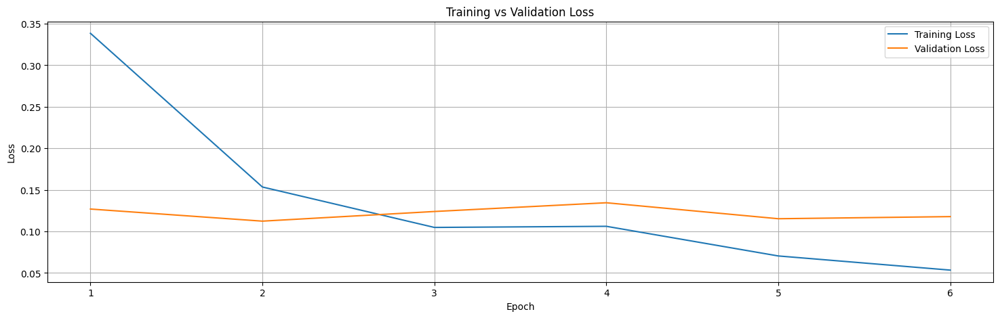

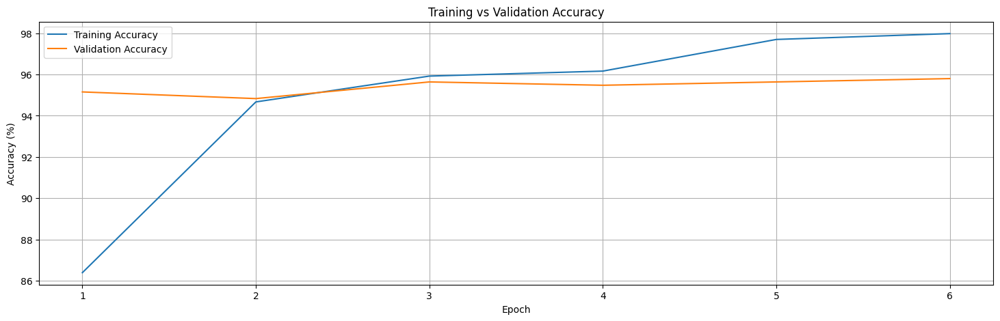

Train RESULTS
Train Loss          : 0.0611
Train Accuracy      : 97.74%
Train Misclassified : 56 / 2476

Validation RESULTS
Validation Loss          : 0.1124
Validation Accuracy      : 94.83%
Validation Misclassified : 32 / 619

Test RESULTS
Test Loss          : 0.3958
Test Accuracy      : 87.25%
Test Misclassified : 44 / 345


VGG19 | stage2 | trainable: head, block5
trainable params: 129,001,476 / 139,586,628
TensorBoard log directory: runs/ft_vgg19_A_s42 - stage2

stage2 | Epoch [01/8] Train Loss: 0.0182 | Val Loss: 0.1908 | Train Acc: 99.27% | Val Acc: 95.64% | LR: 5.0e-05 | 1.0e-05 * BEST
stage2 | Epoch [02/8] Train Loss: 0.0173 | Val Loss: 0.1848 | Train Acc: 99.35% | Val Acc: 95.80% | LR: 5.0e-05 | 1.0e-05 * BEST
stage2 | Epoch [03/8] Train Loss: 0.0901 | Val Loss: 0.1353 | Train Acc: 97.09% | Val Acc: 95.80% | LR: 5.0e-05 | 1.0e-05 * BEST
stage2 | Epoch [04/8] Train Loss: 0.0526 | Val Loss: 0.1169 | Train Acc: 98.06% | Val Acc: 96.77% | LR: 5.0e-05 | 1.0e-05 * BEST
stage2 | Epo

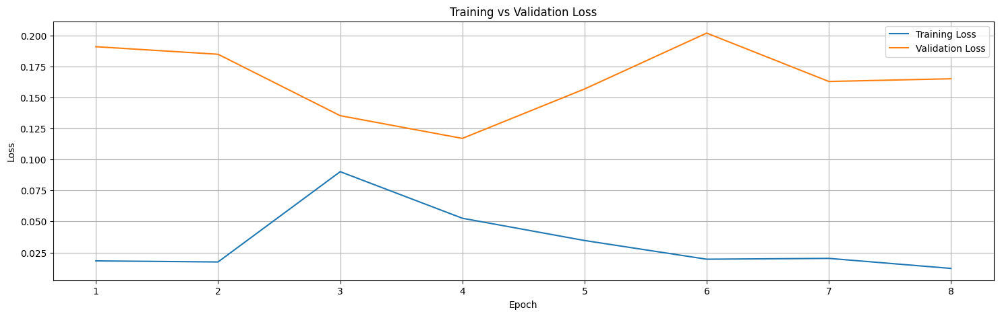

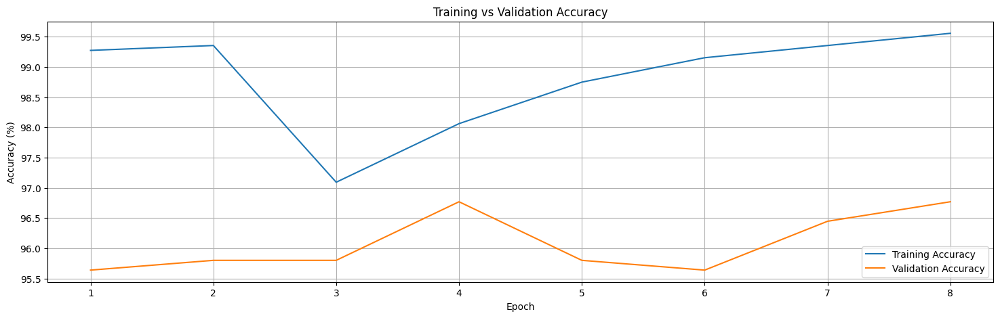

Train RESULTS
Train Loss          : 0.0242
Train Accuracy      : 99.19%
Train Misclassified : 20 / 2476

Validation RESULTS
Validation Loss          : 0.1170
Validation Accuracy      : 96.77%
Validation Misclassified : 20 / 619

Test RESULTS
Test Loss          : 0.3567
Test Accuracy      : 91.88%
Test Misclassified : 28 / 345


VGG19 | stage3 | trainable: head, block5, block4, block3, block2, block1
trainable params: 139,586,628 / 139,586,628
TensorBoard log directory: runs/ft_vgg19_A_s42 - stage3

stage3 | Epoch [01/10] Train Loss: 0.0032 | Val Loss: 0.2178 | Train Acc: 99.88% | Val Acc: 96.77% | LR: 2.0e-05 | 1.0e-05 | 5.0e-06 | 2.5e-06 | 1.0e-06 | 1.0e-06 * BEST
stage3 | Epoch [02/10] Train Loss: 0.0003 | Val Loss: 0.1808 | Train Acc: 100.00% | Val Acc: 96.93% | LR: 2.0e-05 | 1.0e-05 | 5.0e-06 | 2.5e-06 | 1.0e-06 | 1.0e-06 * BEST
stage3 | Epoch [03/10] Train Loss: 0.0065 | Val Loss: 0.2316 | Train Acc: 99.76% | Val Acc: 96.28% | LR: 2.0e-05 | 1.0e-05 | 5.0e-06 | 2.5e-06 | 1.0e-06 | 

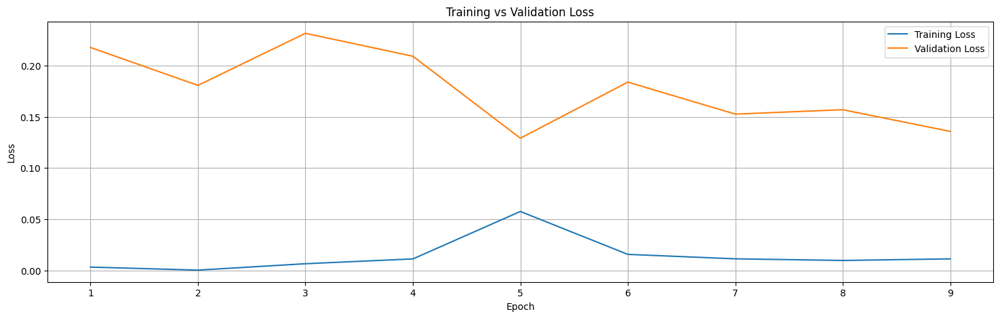

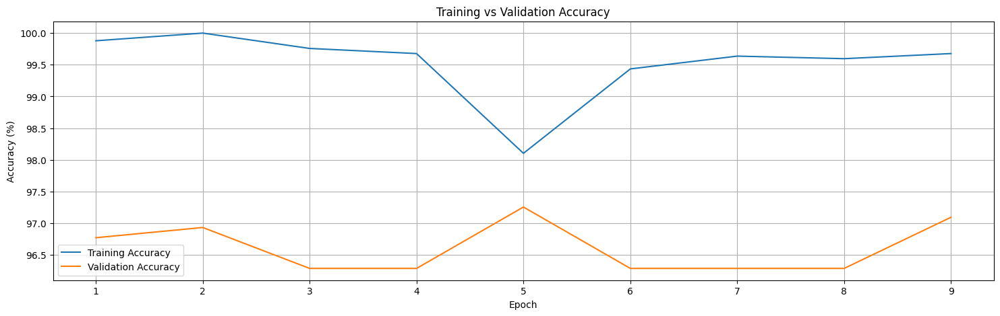

Train RESULTS
Train Loss          : 0.0079
Train Accuracy      : 99.76%
Train Misclassified : 6 / 2476

Validation RESULTS
Validation Loss          : 0.1292
Validation Accuracy      : 97.25%
Validation Misclassified : 17 / 619

Test RESULTS
Test Loss          : 0.4017
Test Accuracy      : 93.04%
Test Misclassified : 24 / 345



,Model,Train Acc,Val Acc,Test Acc,Test Errors,Test Macro-F1,Trainable Params,Total Params,Trainable %,Δ Test Acc,Δ Test Errors
0,vgg19 stage1,97.74,94.83,87.25,44,0.8651,119562244,139586628,85.7,0.00,0
1,vgg19 stage2,99.19,96.77,91.88,28,0.9148,129001476,139586628,92.4,4.63,-16
2,vgg19 stage3,99.76,97.25,93.04,24,0.9265,139586628,139586628,100.0,5.79,-20


In [ ]:
# Option A: ImageNet -> stage1 (head) -> stage2 (top block) -> stage3 (all layers)
vgg_A = run_finetuning("vgg19")

 ## MobileNetV2 - FT


MOBILENETV2 | start: imagenet | tag: mobilenetv2_A_s42

MOBILENETV2 | stage1 | trainable: head
trainable params: 5,124 / 2,228,996
TensorBoard log directory: runs/ft_mobilenetv2_A_s42 - stage1

stage1 | Epoch [01/8] Train Loss: 0.4782 | Val Loss: 0.2266 | Train Acc: 83.89% | Val Acc: 93.38% | LR: 1.0e-03 * BEST
stage1 | Epoch [02/8] Train Loss: 0.1856 | Val Loss: 0.1539 | Train Acc: 94.31% | Val Acc: 95.48% | LR: 1.0e-03 * BEST
stage1 | Epoch [03/8] Train Loss: 0.1536 | Val Loss: 0.1220 | Train Acc: 94.95% | Val Acc: 96.45% | LR: 1.0e-03 * BEST
stage1 | Epoch [04/8] Train Loss: 0.1358 | Val Loss: 0.1085 | Train Acc: 94.99% | Val Acc: 96.12% | LR: 1.0e-03 * BEST
stage1 | Epoch [05/8] Train Loss: 0.1253 | Val Loss: 0.0990 | Train Acc: 95.44% | Val Acc: 96.45% | LR: 1.0e-03 * BEST
stage1 | Epoch [06/8] Train Loss: 0.1084 | Val Loss: 0.0938 | Train Acc: 96.20% | Val Acc: 96.93% | LR: 1.0e-03 * BEST
stage1 | Epoch [07/8] Train Loss: 0.1063 | Val Loss: 0.0857 | Train Acc: 96.24% | Val Acc: 

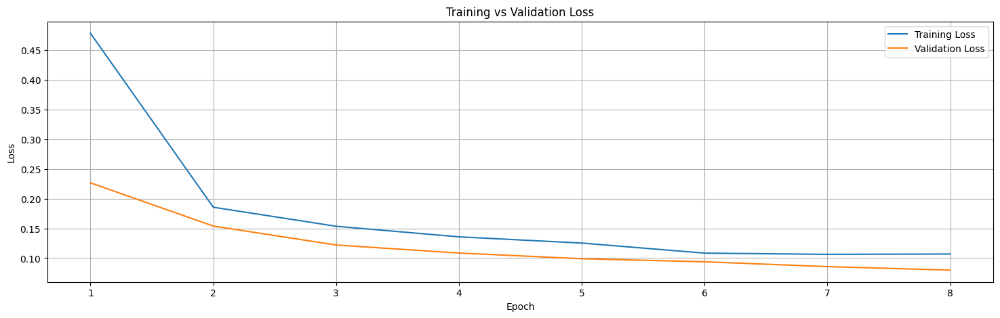

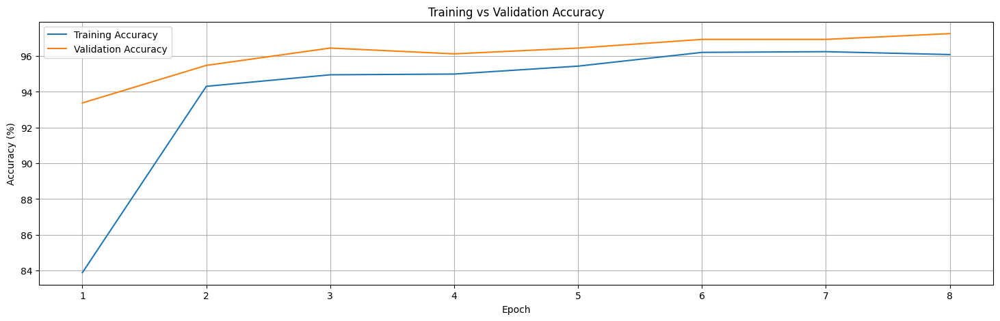

Train RESULTS
Train Loss          : 0.0713
Train Accuracy      : 97.62%
Train Misclassified : 59 / 2476

Validation RESULTS
Validation Loss          : 0.0799
Validation Accuracy      : 97.25%
Validation Misclassified : 17 / 619

Test RESULTS
Test Loss          : 0.1312
Test Accuracy      : 94.78%
Test Misclassified : 18 / 345


MOBILENETV2 | stage2 | trainable: head, top
trainable params: 1,686,468 / 2,228,996
TensorBoard log directory: runs/ft_mobilenetv2_A_s42 - stage2

stage2 | Epoch [01/8] Train Loss: 0.1789 | Val Loss: 0.0835 | Train Acc: 94.51% | Val Acc: 96.61% | LR: 2.0e-04 | 5.0e-05 * BEST
stage2 | Epoch [02/8] Train Loss: 0.0972 | Val Loss: 0.0744 | Train Acc: 96.73% | Val Acc: 96.93% | LR: 2.0e-04 | 5.0e-05 * BEST
stage2 | Epoch [03/8] Train Loss: 0.0668 | Val Loss: 0.0634 | Train Acc: 97.54% | Val Acc: 97.58% | LR: 2.0e-04 | 5.0e-05 * BEST
stage2 | Epoch [04/8] Train Loss: 0.0570 | Val Loss: 0.0619 | Train Acc: 98.22% | Val Acc: 97.42% | LR: 2.0e-04 | 5.0e-05 * BEST
stage2 

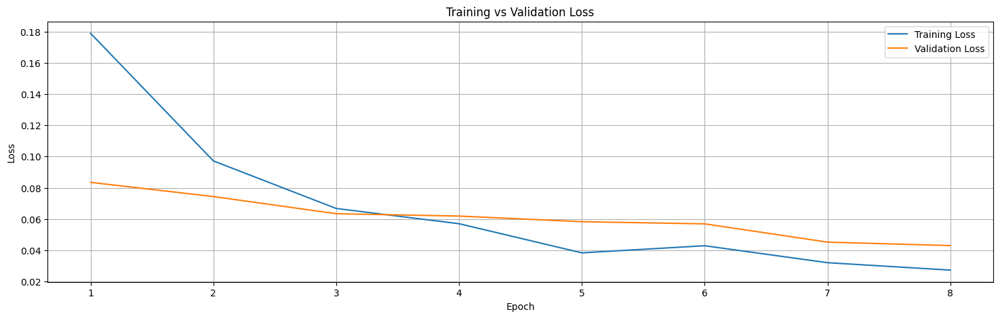

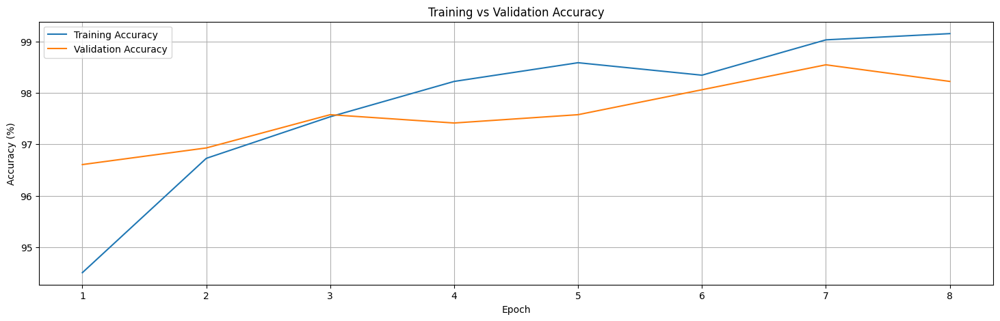

Train RESULTS
Train Loss          : 0.0112
Train Accuracy      : 99.76%
Train Misclassified : 6 / 2476

Validation RESULTS
Validation Loss          : 0.0430
Validation Accuracy      : 98.22%
Validation Misclassified : 11 / 619

Test RESULTS
Test Loss          : 0.1288
Test Accuracy      : 95.94%
Test Misclassified : 14 / 345


MOBILENETV2 | stage3 | trainable: head, top, mid, low
trainable params: 2,228,996 / 2,228,996
TensorBoard log directory: runs/ft_mobilenetv2_A_s42 - stage3

stage3 | Epoch [01/10] Train Loss: 0.0298 | Val Loss: 0.0819 | Train Acc: 99.03% | Val Acc: 97.42% | LR: 5.0e-05 | 2.5e-05 | 1.0e-05 | 5.0e-06 * BEST
stage3 | Epoch [02/10] Train Loss: 0.0239 | Val Loss: 0.1271 | Train Acc: 99.27% | Val Acc: 97.09% | LR: 5.0e-05 | 2.5e-05 | 1.0e-05 | 5.0e-06 
stage3 | Epoch [03/10] Train Loss: 0.0166 | Val Loss: 0.1038 | Train Acc: 99.60% | Val Acc: 97.42% | LR: 5.0e-05 | 2.5e-05 | 1.0e-05 | 5.0e-06 
stage3 | Epoch [04/10] Train Loss: 0.0135 | Val Loss: 0.0499 | Train Acc: 99

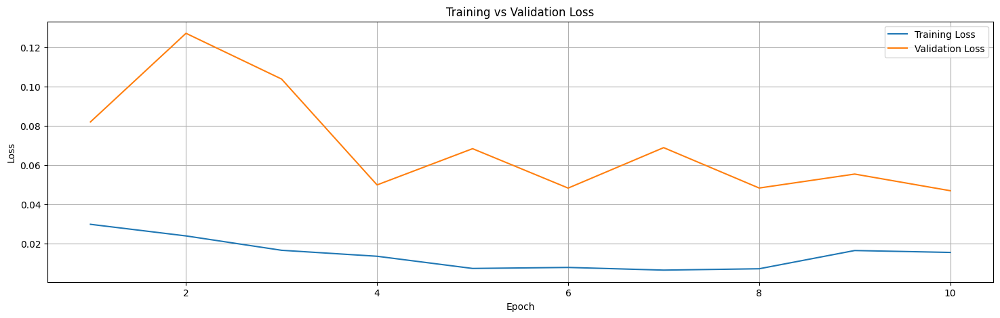

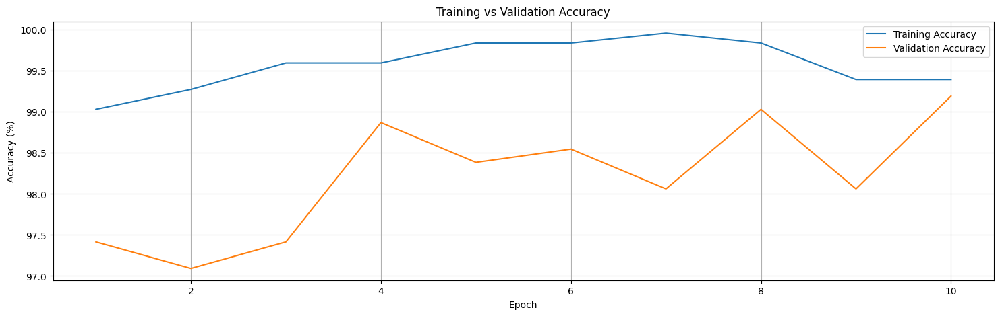

Train RESULTS
Train Loss          : 0.0154
Train Accuracy      : 99.56%
Train Misclassified : 11 / 2476

Validation RESULTS
Validation Loss          : 0.0470
Validation Accuracy      : 99.19%
Validation Misclassified : 5 / 619

Test RESULTS
Test Loss          : 0.1093
Test Accuracy      : 95.65%
Test Misclassified : 15 / 345



,Model,Train Acc,Val Acc,Test Acc,Test Errors,Test Macro-F1,Trainable Params,Total Params,Trainable %,Δ Test Acc,Δ Test Errors
0,mobilenetv2 stage1,97.62,97.25,94.78,18,0.9446,5124,2228996,0.2,0.00,0
1,mobilenetv2 stage2,99.76,98.22,95.94,14,0.9568,1686468,2228996,75.7,1.16,-4
2,mobilenetv2 stage3,99.56,99.19,95.65,15,0.9534,2228996,2228996,100.0,0.87,-3


In [ ]:
mob_A = run_finetuning("mobilenetv2")

## ResNet50 - FT


RESNET50 | start: imagenet | tag: resnet50_A_s42

RESNET50 | stage1 | trainable: head
trainable params: 8,196 / 23,516,228
TensorBoard log directory: runs/ft_resnet50_A_s42 - stage1

stage1 | Epoch [01/8] Train Loss: 0.4224 | Val Loss: 0.1941 | Train Acc: 85.30% | Val Acc: 94.02% | LR: 1.0e-03 * BEST
stage1 | Epoch [02/8] Train Loss: 0.1816 | Val Loss: 0.1367 | Train Acc: 93.74% | Val Acc: 94.02% | LR: 1.0e-03 * BEST
stage1 | Epoch [03/8] Train Loss: 0.1555 | Val Loss: 0.1210 | Train Acc: 94.47% | Val Acc: 94.83% | LR: 1.0e-03 * BEST
stage1 | Epoch [04/8] Train Loss: 0.1364 | Val Loss: 0.1139 | Train Acc: 94.87% | Val Acc: 95.96% | LR: 1.0e-03 * BEST
stage1 | Epoch [05/8] Train Loss: 0.1231 | Val Loss: 0.0996 | Train Acc: 95.48% | Val Acc: 96.12% | LR: 1.0e-03 * BEST
stage1 | Epoch [06/8] Train Loss: 0.1146 | Val Loss: 0.1230 | Train Acc: 95.64% | Val Acc: 94.83% | LR: 1.0e-03 
stage1 | Epoch [07/8] Train Loss: 0.1078 | Val Loss: 0.0902 | Train Acc: 95.96% | Val Acc: 96.77% | LR: 1.0e

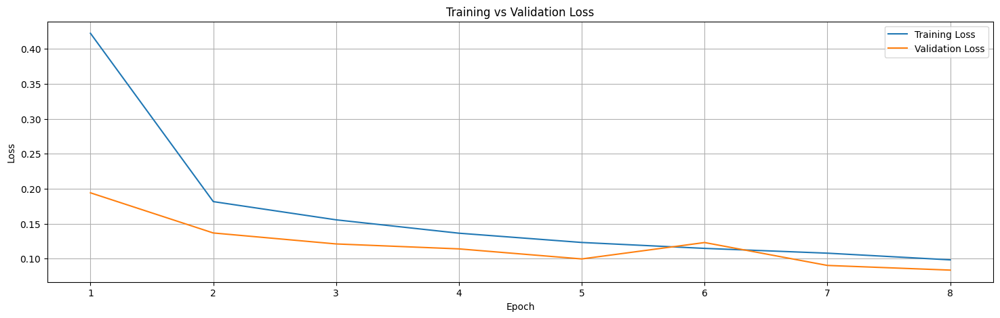

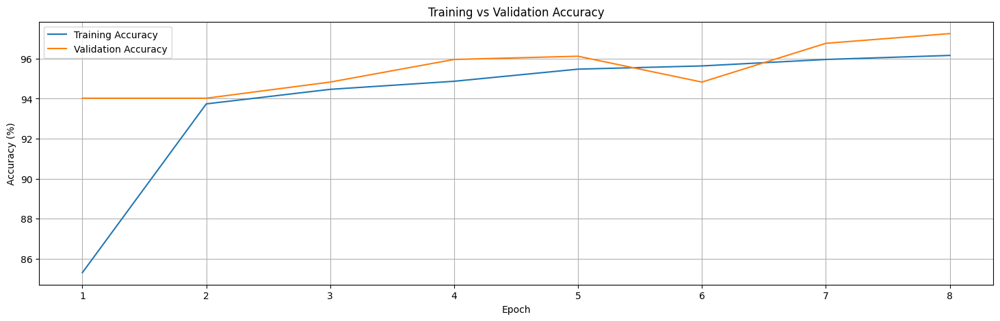

Train RESULTS
Train Loss          : 0.0688
Train Accuracy      : 97.58%
Train Misclassified : 60 / 2476

Validation RESULTS
Validation Loss          : 0.0836
Validation Accuracy      : 97.25%
Validation Misclassified : 17 / 619

Test RESULTS
Test Loss          : 0.1820
Test Accuracy      : 93.04%
Test Misclassified : 24 / 345


RESNET50 | stage2 | trainable: head, layer4
trainable params: 14,972,932 / 23,516,228
TensorBoard log directory: runs/ft_resnet50_A_s42 - stage2

stage2 | Epoch [01/8] Train Loss: 0.1382 | Val Loss: 0.0454 | Train Acc: 94.83% | Val Acc: 98.22% | LR: 2.0e-04 | 5.0e-05 * BEST
stage2 | Epoch [02/8] Train Loss: 0.0500 | Val Loss: 0.0405 | Train Acc: 98.34% | Val Acc: 98.38% | LR: 2.0e-04 | 5.0e-05 * BEST
stage2 | Epoch [03/8] Train Loss: 0.0272 | Val Loss: 0.0384 | Train Acc: 99.11% | Val Acc: 98.22% | LR: 2.0e-04 | 5.0e-05 * BEST
stage2 | Epoch [04/8] Train Loss: 0.0162 | Val Loss: 0.0371 | Train Acc: 99.52% | Val Acc: 98.55% | LR: 2.0e-04 | 5.0e-05 * BEST
stage2 |

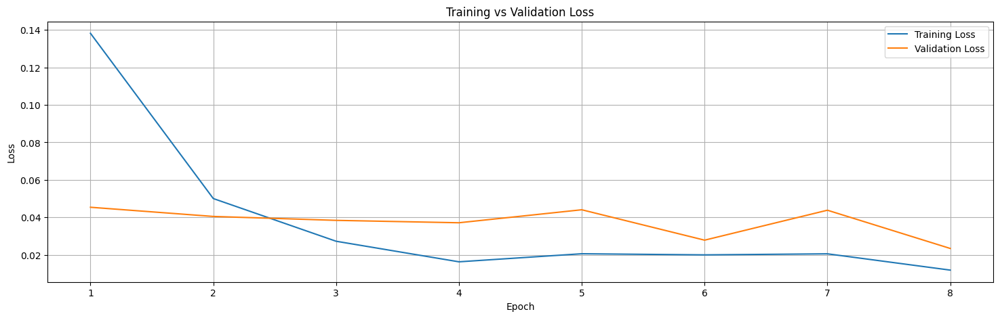

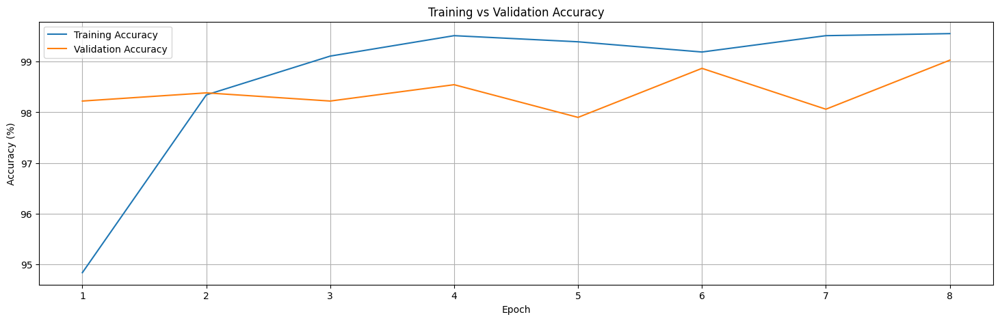

Train RESULTS
Train Loss          : 0.0025
Train Accuracy      : 100.00%
Train Misclassified : 0 / 2476

Validation RESULTS
Validation Loss          : 0.0234
Validation Accuracy      : 99.03%
Validation Misclassified : 6 / 619

Test RESULTS
Test Loss          : 0.2919
Test Accuracy      : 93.33%
Test Misclassified : 23 / 345


RESNET50 | stage3 | trainable: head, layer4, layer3, layer2, early
trainable params: 23,516,228 / 23,516,228
TensorBoard log directory: runs/ft_resnet50_A_s42 - stage3

stage3 | Epoch [01/10] Train Loss: 0.0123 | Val Loss: 0.0392 | Train Acc: 99.68% | Val Acc: 98.87% | LR: 5.0e-05 | 2.5e-05 | 1.0e-05 | 5.0e-06 | 5.0e-06 * BEST
stage3 | Epoch [02/10] Train Loss: 0.0075 | Val Loss: 0.0575 | Train Acc: 99.72% | Val Acc: 96.93% | LR: 5.0e-05 | 2.5e-05 | 1.0e-05 | 5.0e-06 | 5.0e-06 
stage3 | Epoch [03/10] Train Loss: 0.0054 | Val Loss: 0.0593 | Train Acc: 99.88% | Val Acc: 98.22% | LR: 5.0e-05 | 2.5e-05 | 1.0e-05 | 5.0e-06 | 5.0e-06 
stage3 | Epoch [04/10] Train Loss:

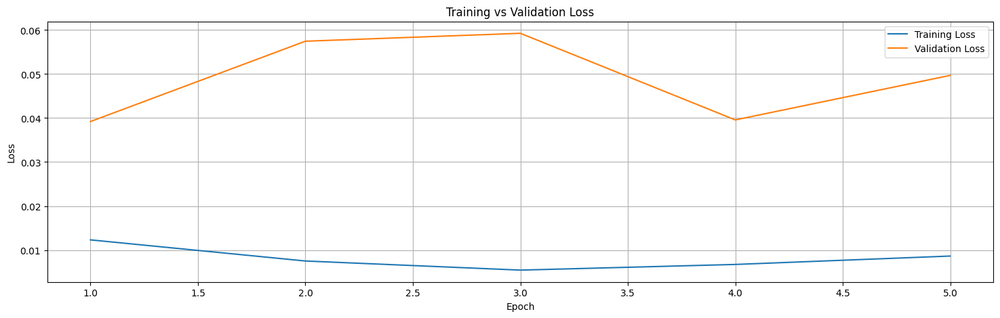

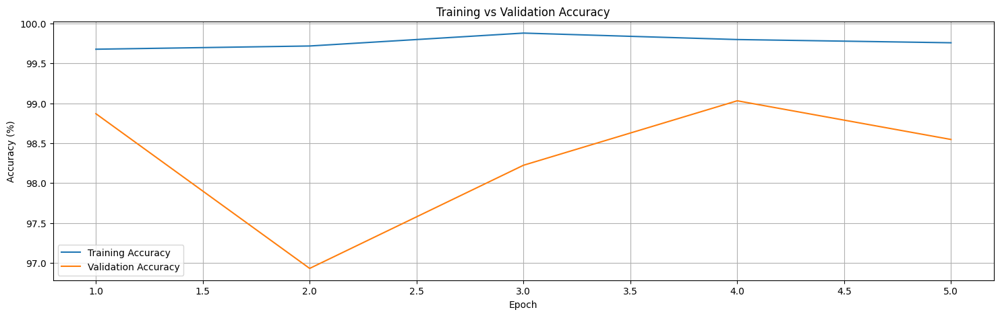

Train RESULTS
Train Loss          : 0.0022
Train Accuracy      : 100.00%
Train Misclassified : 0 / 2476

Validation RESULTS
Validation Loss          : 0.0392
Validation Accuracy      : 98.87%
Validation Misclassified : 7 / 619

Test RESULTS
Test Loss          : 0.2772
Test Accuracy      : 93.62%
Test Misclassified : 22 / 345



,Model,Train Acc,Val Acc,Test Acc,Test Errors,Test Macro-F1,Trainable Params,Total Params,Trainable %,Δ Test Acc,Δ Test Errors
0,resnet50 stage1,97.58,97.25,93.04,24,0.9264,8196,23516228,0.0,0.00,0
1,resnet50 stage2,100.00,99.03,93.33,23,0.9294,14972932,23516228,63.7,0.29,-1
2,resnet50 stage3,100.00,98.87,93.62,22,0.9321,23516228,23516228,100.0,0.58,-2


In [ ]:
r50_A = run_finetuning("resnet50")

## Model Comparison: Ninjacart 4-class classifier

**Legend:** Acc = accuracy (%). Precision, Recall and F1 are macro-averaged on the **test** set (345 images). FT = fine-tuned from ImageNet: stage 1 trains the head only, stage 2 adds the top block, stage 3 trains all layers.

| Model | Train Acc | Val Acc | Test Acc | Test Precision | Test Recall | Test F1 | Test Errors |
|---|---|---|---|---|---|---|---|
| CustomCNN (baseline) | 90.06 | 88.53 | 84.93 | 0.8622 | 0.8388 | 0.8379 | 52 |
| CustomCNN (BN + dropout) | 94.14 | 93.05 | 92.46 | 0.9206 | 0.9183 | 0.9187 | 26 |
| CustomCNN (BN + dropout + class weights) | 94.10 | 92.41 | 93.62 | 0.9356 | 0.9323 | 0.9314 | 22 |
| VGG19 (base) | 88.33 | 84.33 | 80.87 | 0.8075 | 0.7949 | 0.7948 | 66 |
| VGG19 FT stage 1 | 97.74 | 94.83 | 87.25 | — | — | 0.8651 | 44 |
| VGG19 FT stage 2 | 99.19 | 96.77 | 91.88 | — | — | 0.9148 | 28 |
| VGG19 FT stage 3 | 99.76 | 97.25 | 93.04 | — | — | 0.9265 | 24 |
| MobileNetV2 (base) | 99.76 | 98.06 | 95.65 | 0.9559 | 0.9524 | 0.9527 | 15 |
| MobileNetV2 FT stage 1 | 97.62 | 97.25 | 94.78 | — | — | 0.9446 | 18 |
| MobileNetV2 FT stage 2 | 99.76 | 98.22 | 95.94 | — | — | 0.9568 | 14 |
| **MobileNetV2 FT stage 3 (recommended)** | **99.56** | **99.19** | **95.65** | — | — | **0.9534** | **15** |
| ResNet-50 (base) | 99.39 | 96.77 | 96.23 | 0.9595 | 0.9588 | 0.9590 | 13 |
| ResNet-50 FT stage 1 | 97.58 | 97.25 | 93.04 | — | — | 0.9264 | 24 |
| ResNet-50 FT stage 2 | 100.00 | 99.03 | 93.33 | — | — | 0.9294 | 23 |
| ResNet-50 FT stage 3 | 100.00 | 98.87 | 93.62 | — | — | 0.9321 | 22 |

## Deployment cost (per architecture)

| Architecture | Params | Size (fp32) | Mobile suitability |
|---|---|---|---|
| CustomCNN (BN + dropout) | 0.46M | 1.8 MB | Small, but about 2.4x the compute of MobileNetV2 |
| **MobileNetV2** | **2.23M** | **8.9 MB** | **Built for mobile** |
| ResNet-50 | 23.52M | 94 MB | Heavy |
| VGG19 | 139.59M | 558 MB | Not practical |

The FT rows of each architecture have the same size and compute as its base row. Size is params x 4 bytes.

## Recommendation: MobileNetV2, FT stage 3

| Factor | Evidence |
|---|---|
| Accuracy | Test 95.65% (15 errors), F1 0.9534. The best model (ResNet-50 base, 13 errors) is only 2 images better, which is inside test noise (up and above 4 images on 345). |
| Validation | Highest of all models: 99.19% (5 errors out of 619). |
| Size | 8.9 MB vs 94 MB for ResNet-50 (about 10x smaller). |
| Compute | faster on-device and easier on battery. |
| Mobile path | A standard on-device architecture.

**When to choose something else**

| Situation | Pick |
|---|---|
| Server or GPU deployment where size and latency don't matter | **ResNet-50 (base)**: best test accuracy and F1, and the smallest val -> test gap (96.77 -> 96.23) |
| Tiny model, accuracy a secondary concern | CustomCNN + class weights: 1.8 MB, but about 2 points lower test accuracy, and not obviously faster |
| Never | VGG19: 558 MB, and its best result (93.04%) is below the others |



In [ ]:
mob_A.keys()

dict_keys(['mean', 'std', 'stage1', 'stage2', 'stage3', 'model', 'summary'])

In [ ]:
mob_A['stage3'].keys()

dict_keys(['ckpt', 'history', 'trainable_params', 'total_params', 'y_true', 'y_pred', 'mis', 'correct'])

In [ ]:
len(mob_A['stage3']['ckpt'])

44

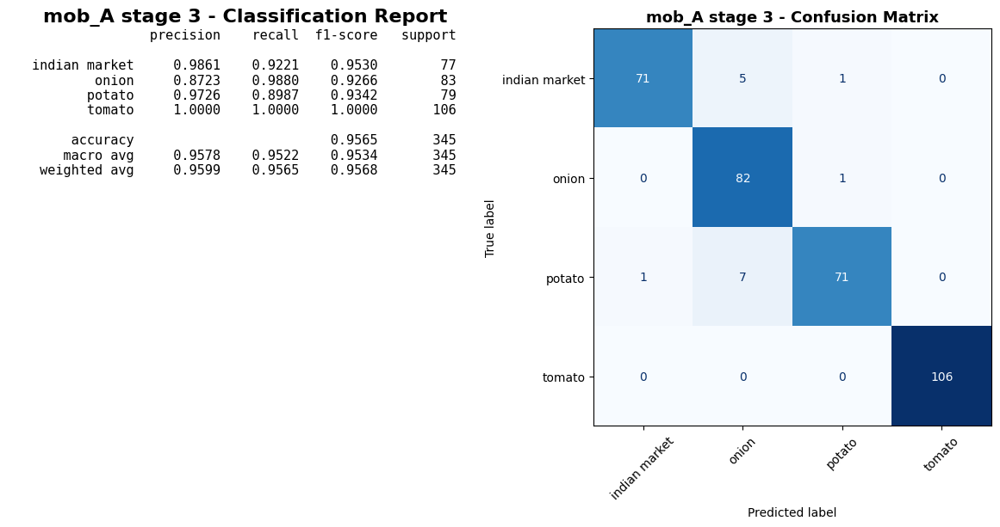

In [ ]:
r2 = mob_A["stage3"]
cm, re = model_report(r2["y_true"]["Test"], r2["y_pred"]["Test"], class_names, model_name="mob_A stage 3")

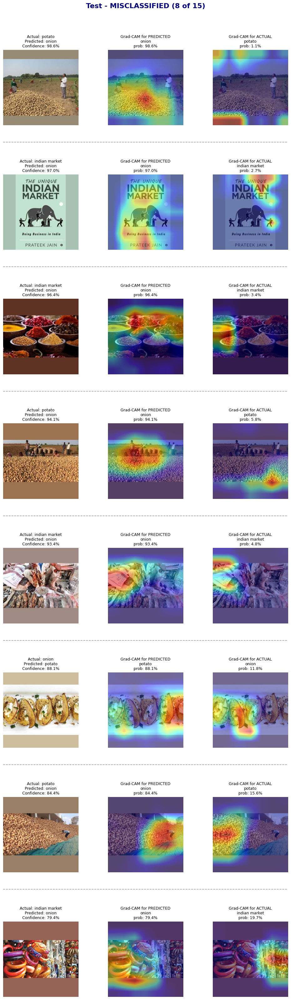

In [ ]:
m2 = load_model("mobilenetv2", mob_A["stage3"]["ckpt"])
show_gradcam_by_split(r2["mis"], r2["correct"], class_names, m2,
                      ARCHS["mobilenetv2"]["gradcam_layer"](m2), mob_A["mean"], mob_A["std"],
                      splits=["Test"], max_img=8, show=("mis",), cam_for="both", order = "high", seed = 99)

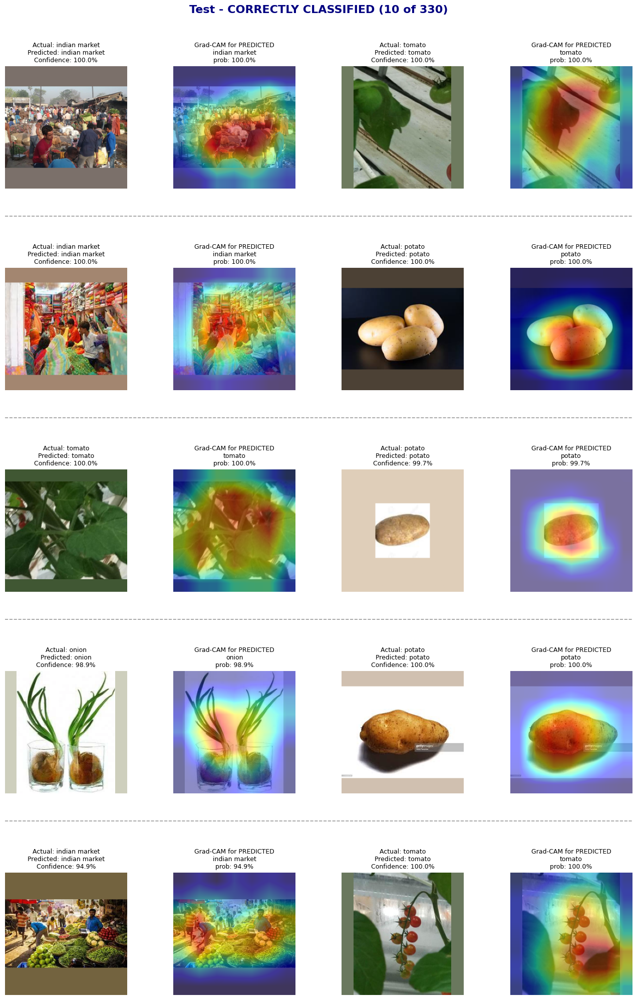

In [ ]:
show_gradcam_by_split(r2["mis"], r2["correct"], class_names, m2,
                      ARCHS["mobilenetv2"]["gradcam_layer"](m2), mob_A["mean"], mob_A["std"],
                      splits=["Test"], max_img=10, show=("correct",), cam_for="both", order = "random", seed = 34)


## Final Takeaway

- **Fine-tuning helps VGG19 a lot** (test 80.87% -> 93.04%). For MobileNetV2 and ResNet-50, the base run already matches or beats staged fine-tuning on test (95.65 vs 95.65, and 96.23 vs 93.62).
- **Validation is optimistic for the fine-tuned models.** ResNet-50 FT stage 3 reaches 100% train and 98.87% val, but only 93.62% test.
- **Most test gaps here are 1–3 images.** MobileNetV2 stages 2 and 3 and the base model, and ResNet-50 base, are kind of similar interms of result.
- **Before shipping:**  Every row is a single run (one seed). I picked the architecture using val and test together. we should run the best model using multiple seeds and compare outputs.